# Lab 2 : OD Matrices analytics

## Setup of datasets and visualization

In [1]:
%pip install geopandas "folium>=0.12" matplotlib mapclassify pymongo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pymongo as pm
from pprint import pprint
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timezone
import geopandas as gpd
from shapely.geometry import box
from geopandas import GeoDataFrame
from shapely.geometry import box
from branca.colormap import linear
from IPython.display import display
import seaborn as sns
import ipywidgets as widgets
from itertools import combinations
import json, os
from matplotlib.path import Path
from matplotlib.colors import LogNorm
from scipy.spatial.distance import jensenshannon

os.makedirs('out', exist_ok=True)

In [3]:
client = pm.MongoClient(
 'bigdatadb.polito.it',
 ssl=True,
 authSource='carsharing',
 username='ictts',
 password='Ict4SM22!',
 tlsAllowInvalidCertificates=True
)

In [4]:
db= client['carsharing']
pb_coll = db['ictts_PermanentBookings']
pb_coll_enjoy= db['ictts_enjoy_PermanentBookings']

In [5]:
def load_wtime(db, coll, carsharing=True):
    if carsharing:
        pipe = [
            {
                "$match": {
                    "driving.duration": {"$gt": 0},
                    "driving.distance": {"$gt": 0}
                }
            },
            {
                "$project": {
                    "_id": 0,
                    "init_time": 1,
                    "final_time": 1,
                    "duration": "$driving.duration",
                    "day": {
                        "$dateToString": {
                            "date": "$init_date",
                            "format": "%Y-%m-%d"
                        }
                    },
                    "week": {"$isoWeek": "$init_date"},
                    "iso_year": {"$isoWeekYear": "$init_date"},
                    "dow": {"$isoDayOfWeek": "$init_date"},
                    "hour": {"$hour": "$init_date"},
                    "vendor": 1,
                    "init_address": 1,
                    "final_address": 1,
                    "plate": 1,
                    "init_loc": 1,
                    "final_loc": 1,
                    "driving": 1,
                    "walking": 1,
                    'init_date':1
                }
            }
        ]

    else:
        raise NotImplementedError(
            "Non-carsharing data processing is not implemented yet."
        )

    collection = db[coll] if isinstance(coll, str) else coll
    df = pd.DataFrame(collection.aggregate(pipe, allowDiskUse=True))

    if df.empty:
        print("Warning: MongoDB query returned no documents.")
        return df

    df["duration_min"] = df["duration"] / 60

    df["driving_distance_km"] = df["driving"].apply(
        lambda x: x["distance"] / 1000
        if isinstance(x, dict) else np.nan
    )

    df["walking_duration_min"] = df["walking"].apply(
        lambda x: x["duration"] / 60
        if isinstance(x, dict) else np.nan
    )

    return df

# Q1

For this question we started to look at the data to see if we needed to adapt our filtering from the first lab.

In [6]:
def load_raw(coll, city="Torino"):
    pipe = [
        {
            "$match": {
                "city": city,
               }
        },
        {"$project": {
            "_id": 0,
            "plate": 1,
            "init_date": 1, "final_date": 1,
            "init_time": 1, "final_time": 1,
            "init_loc": 1, "final_loc": 1,
            "drv_dur": "$driving.duration",
            "drv_dist": "$driving.distance",
        }},
    ]
    df = pd.DataFrame(coll.aggregate(pipe, allowDiskUse=True))
    df["rental_min"] = (df["final_time"] - df["init_time"]) / 60
    df["drv_dist_km"] = df["drv_dist"] / 1000
    df["init_date"] = pd.to_datetime(df["init_date"])
    # coordinates to test "start == end"
    df["same_loc"] = df["init_loc"].apply(lambda x: tuple(x["coordinates"])) == \
                     df["final_loc"].apply(lambda x: tuple(x["coordinates"]))
    return df.drop(columns=["init_loc", "final_loc"])

raw = {
    "Car2Go": load_raw(pb_coll),
    "Enjoy":  load_raw(pb_coll_enjoy),
}

def explore(df, name):
    print(f"--- {name} ---")
    print("duration < 1 min      :", (df.rental_min < 1).sum())
    print("duration > 3 h        :", (df.rental_min > 180).sum())
    print("duration > 24 h       :", (df.rental_min > 1440).sum())
    print("distance <= 0         :", (df.drv_dist <= 0).sum())
    print("start == end          :", df.same_loc.sum())
    print(df[["rental_min", "drv_dist_km"]].describe(percentiles=[.01, .05, .5, .95, .99]))

for name, df in raw.items():
    explore(df, name)

--- Car2Go ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 82477
start == end          : 0
          rental_min    drv_dist_km
count  121667.000000  121667.000000
mean       20.889914       1.251278
std         9.849642       2.200316
min         2.100000      -0.001000
1%          4.750000      -0.001000
5%          7.633333      -0.001000
50%        19.433333      -0.001000
95%        39.650000       5.789000
99%        51.750000       8.347680
max        59.983333      33.401000
--- Enjoy ---
duration < 1 min      : 0
duration > 3 h        : 0
duration > 24 h       : 0
distance <= 0         : 61447
start == end          : 0
         rental_min   drv_dist_km
count  97173.000000  97173.000000
mean      23.405766      1.494120
std       10.423864      2.434082
min        3.066667     -0.001000
1%         7.616667     -0.001000
5%         8.466667     -0.001000
50%       20.533333     -0.001000
95%       44.316667      6.278000
9

We can see that there is a lot of duration below 0 so we just filter it in the pipe.\
The only filter needed is a distance one. It cut 67.79% data for the car2go database and 63.23% for the enjoy Database.

For the rest of the question we only used the filtering on the distance and the duration that must be >0.

In [7]:
#we add the columns for the coordinates
bookings = {'car2go': load_wtime(db, pb_coll), 'enjoy': load_wtime(db, pb_coll_enjoy)}
for name, df in bookings.items():
    
    df['orig_lon'] = df['init_loc'].apply(lambda p: p['coordinates'][0])
    df['orig_lat'] = df['init_loc'].apply(lambda p: p['coordinates'][1])
    df['dest_lon'] = df['final_loc'].apply(lambda p: p['coordinates'][0])
    df['dest_lat'] = df['final_loc'].apply(lambda p: p['coordinates'][1])
    
    print(f'{name}: {len(df)} rentals kept')

car2go: 39190 rentals kept
enjoy: 35726 rentals kept


In [8]:
# order of the features in TorinoZonescol.geojson (checked against the IMQ zone list)
FILE_ORDER = [f'Q{i:03d}' for i in range(1, 20)] + ['Q021', 'Q022', 'Q020', 'Q023']

def load_zones(path, names_path='data/IMQ/IMQData/tab_zone_IMQ.csv'):
    """23 zones of Torino: {code: geometry}, sorted list of codes, {code: name}."""
    with open(path) as f:
        fc = json.load(f)
    zones = {code: feature['geometry'] for code, feature in zip(FILE_ORDER, fc['features'])}
    table = pd.read_csv(names_path, encoding='latin-1', dtype=str).set_index('COD_ZONA')['nome_zona']
    names = {code: table[code].replace('TORINO - ', '').title() for code in zones}
    return zones, sorted(zones), names


def point_zone(lon, lat, zones):
    """Zone code of each point (lon, lat); None if outside all zones."""
    pts = np.column_stack([np.asarray(lon, float), np.asarray(lat, float)])
    out = np.full(len(pts), None, dtype=object)
    for code in sorted(zones):
        geom = zones[code]
        polys = geom['coordinates'] if geom['type'] == 'MultiPolygon' else [geom['coordinates']]
        inside = np.zeros(len(pts), dtype=bool)
        for poly in polys:
            m = Path(poly[0]).contains_points(pts)
            for hole in poly[1:]:
                m &= ~Path(hole).contains_points(pts)
            inside |= m
        out[inside & pd.isna(out)] = code
    return out


def assign_zones(df, zones):
    """Adds orig/dest zone codes and keeps only trips starting and ending inside the zones."""
    df = df.copy()
    df['orig'] = point_zone(df.orig_lon, df.orig_lat, zones)
    df['dest'] = point_zone(df.dest_lon, df.dest_lat, zones)
    inside = df.dropna(subset=['orig', 'dest'])
    print(f'{len(inside)}/{len(df)} trips inside the Torino zones ({len(inside) / len(df):.1%})')
    return inside

In [9]:
def add_time_columns(df):
    """Date, hour, day of week (0 = Monday) and calendar (ISO) week of each trip."""
    df = df.copy()
    d = pd.to_datetime(df['init_date'])
    df['date'] = d.dt.strftime('%Y-%m-%d')
    df['hour'] = d.dt.hour
    df['dow'] = d.dt.dayofweek
    df['week'] = d.dt.isocalendar().week.astype(int)
    return df


def select_period(df, days='all', hours=None, weeks=None):
    """days: 'all', 'weekdays' or 'weekend'; hours: (start, end), e.g. (22, 6) goes over midnight;
    weeks: list of calendar weeks."""
    mask = pd.Series(True, index=df.index)
    if days == 'weekdays':
        mask &= df.dow < 5
    elif days == 'weekend':
        mask &= df.dow >= 5
    if hours is not None:
        start, end = hours
        if start <= end:
            mask &= (df.hour >= start) & (df.hour < end)
        else:
            mask &= (df.hour >= start) | (df.hour < end)
    if weeks is not None:
        mask &= df.week.isin(weeks)
    return df[mask]

In [10]:
def od_matrix(df, zones_list, norm=True):
    """23 x 23 OD matrix (pivot table of trip counts); pairs without trips = 0; normalized to sum 1."""
    m = pd.pivot_table(df, index='orig', columns='dest', values='duration_min',
                       aggfunc='count', fill_value=0)
    m = m.reindex(index=zones_list, columns=zones_list, fill_value=0)
    m.index.name, m.columns.name = 'orig', 'dest'
    return m / m.values.sum() if norm else m


def tvd(A, B):
    """Total variation distance in %: 0 = identical, 100 = completely different."""
    return 0.5 * np.abs(A.values - B.values).sum() * 100


def top_changes(A, B, label_a='A', label_b='B', n=10):
    """The n OD pairs whose share of trips changes the most between A and B (percentage points)."""
    D = (A - B).stack()
    idx = D.abs().sort_values(ascending=False).index[:n]
    return pd.DataFrame({
        'origin': [f'{o} {ZONE_NAMES[o]}' for o, _ in idx],
        'destination': [f'{d} {ZONE_NAMES[d]}' for _, d in idx],
        f'{label_a} (%)': [A.loc[o, d] * 100 for o, d in idx],
        f'{label_b} (%)': [B.loc[o, d] * 100 for o, d in idx],
        'difference (p.p.)': [D[(o, d)] * 100 for o, d in idx],
    }).round(2)

In [11]:
from matplotlib.colors import LogNorm

def zone_labels(codes):
    return [f'{c} {ZONE_NAMES.get(c, "")}' for c in codes]


def plot_heatmaps(mats, title='', fname=None):
    """mats = {label: OD matrix}, side by side, same log colour scale; cells with no trips in grey."""
    vals = np.concatenate([m.values.ravel() for m in mats.values()])
    pos = vals[vals > 0]
    norm = LogNorm(vmin=np.percentile(pos, 1), vmax=pos.max())
    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad('#dddddd')
    fig, axes = plt.subplots(1, len(mats), figsize=(7.5 * len(mats), 7), squeeze=False, constrained_layout=True)
    for ax, (name, m) in zip(axes[0], mats.items()):
        im = ax.imshow(np.ma.masked_where(m.values <= 0, m.values), cmap=cmap, norm=norm)
        ax.set_title(name, fontsize=12)
        ax.set_xticks(range(len(m.columns))); ax.set_xticklabels(zone_labels(m.columns), rotation=90, fontsize=7)
        ax.set_yticks(range(len(m.index))); ax.set_yticklabels(zone_labels(m.index), fontsize=7)
        ax.set_xlabel('destination zone'); ax.set_ylabel('origin zone')
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.7, label='fraction of trips (log scale)')
    fig.suptitle(title, fontsize=14)
    if fname: fig.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()


def plot_difference(A, B, title='', fname=None):
    """Heatmap of A - B: red = more trips in A, blue = more in B."""
    D = A - B
    lim = np.abs(D.values).max()
    plt.figure(figsize=(8, 7))
    plt.imshow(D.values, cmap='RdBu_r', vmin=-lim, vmax=lim)
    plt.colorbar(label='A − B')
    plt.xticks(range(len(D.columns)), zone_labels(D.columns), rotation=90, fontsize=7)
    plt.yticks(range(len(D.index)), zone_labels(D.index), fontsize=7)
    plt.xlabel('destination zone'); plt.ylabel('origin zone'); plt.title(title)
    if fname: plt.savefig(f'out/{fname}.png', dpi=200, bbox_inches='tight')
    plt.show()

### OD matrices on the 23 zones (all trips)

38941/39190 trips inside the Torino zones (99.4%)
35541/35726 trips inside the Torino zones (99.5%)


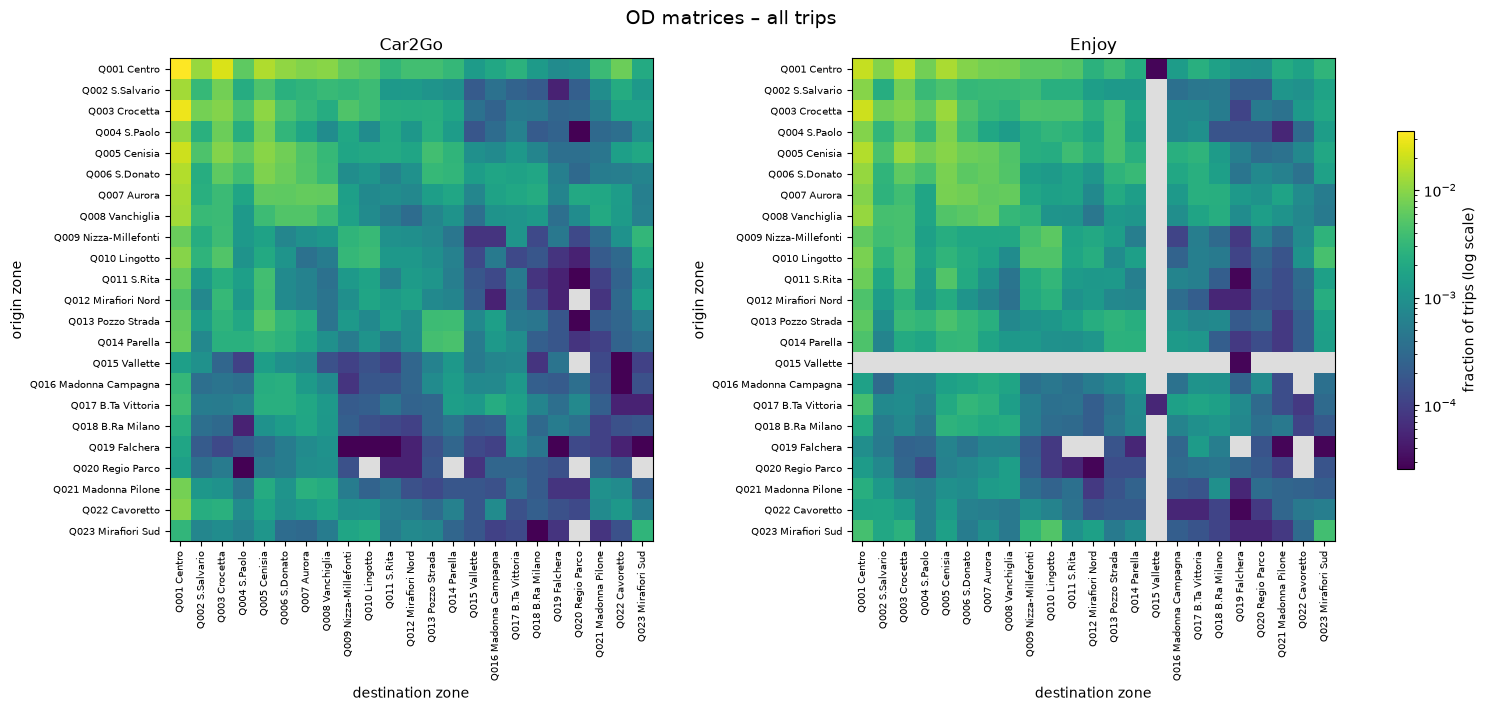

In [12]:
zones, ZONES, ZONE_NAMES = load_zones('data/IMQ/Zone/TorinoZonescol.geojson')
trips = {name: add_time_columns(assign_zones(df, zones)) for name, df in bookings.items()}

od_all = {name: od_matrix(df, ZONES) for name, df in trips.items()}
plot_heatmaps({'Car2Go': od_all['car2go'], 'Enjoy': od_all['enjoy']}, 'OD matrices – all trips', 'task1_od')

## Q1a – Different periods
Weekdays vs weekends, daytime (6–22h) vs night-time, for each platform.

In [13]:
DAY_HOURS = (6, 22)
PERIODS = {
    'Weekdays':   dict(days='weekdays'),
    'Weekends':   dict(days='weekend'),
    'Daytime':    dict(hours=DAY_HOURS),
    'Night-time': dict(hours=DAY_HOURS[::-1]),
}

od_periods = {}
for vendor, df in trips.items():
    od_periods[vendor] = {}
    for name, kw in PERIODS.items():
        sel = select_period(df, **kw)
        od_periods[vendor][name] = od_matrix(sel, ZONES)
        print(f'{vendor:7s} {name:11s}: {len(sel):6d} trips')

car2go  Weekdays   :  29027 trips
car2go  Weekends   :   9914 trips
car2go  Daytime    :  28240 trips
car2go  Night-time :  10701 trips
enjoy   Weekdays   :  26549 trips
enjoy   Weekends   :   8992 trips
enjoy   Daytime    :  23929 trips
enjoy   Night-time :  11612 trips


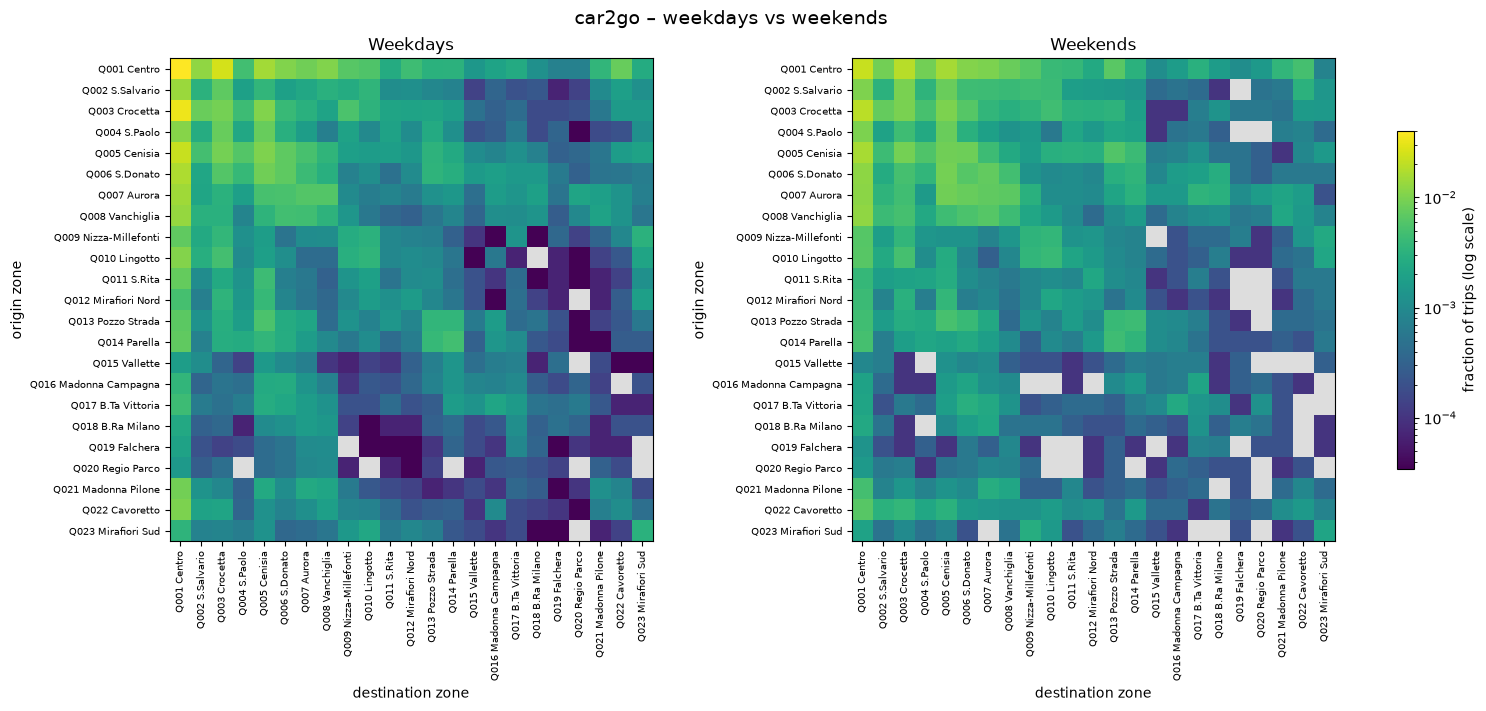

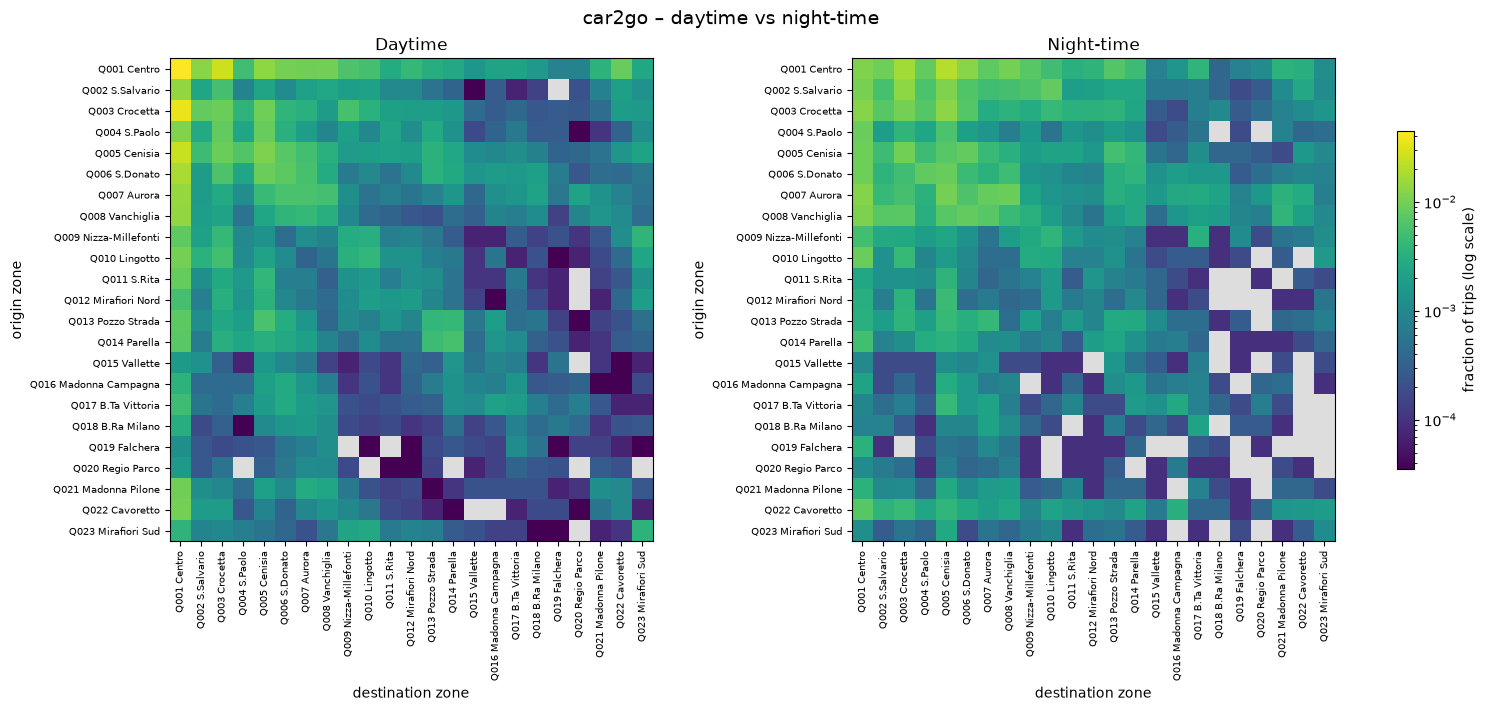

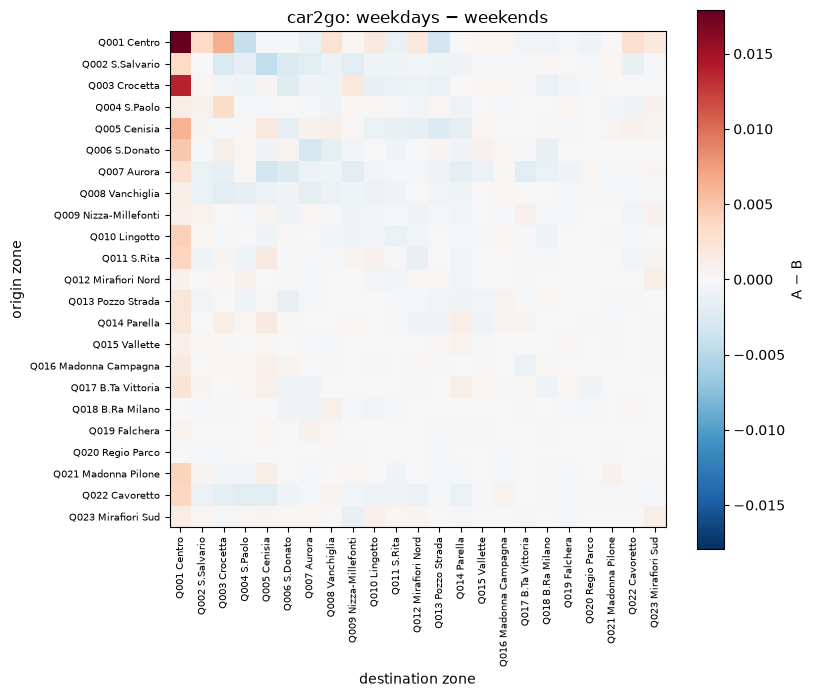

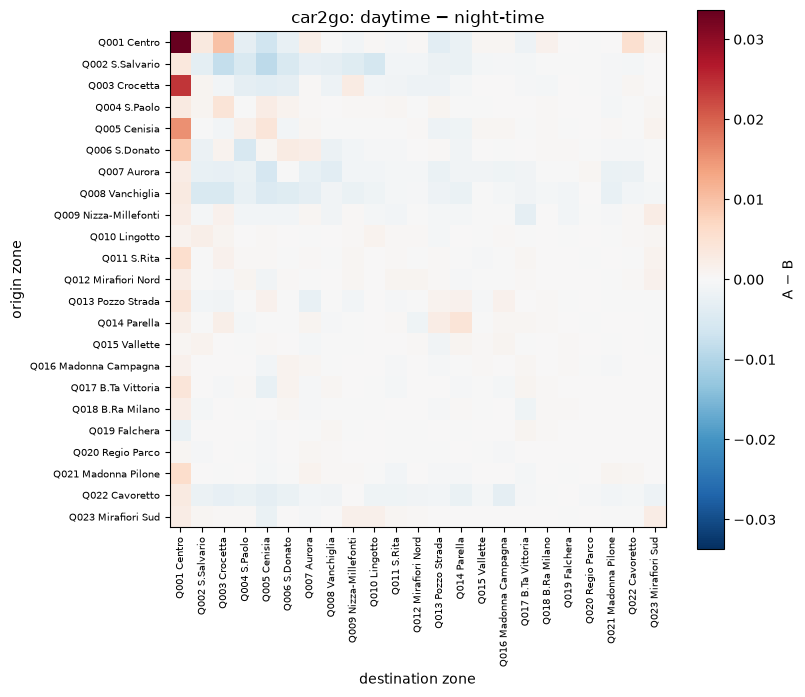

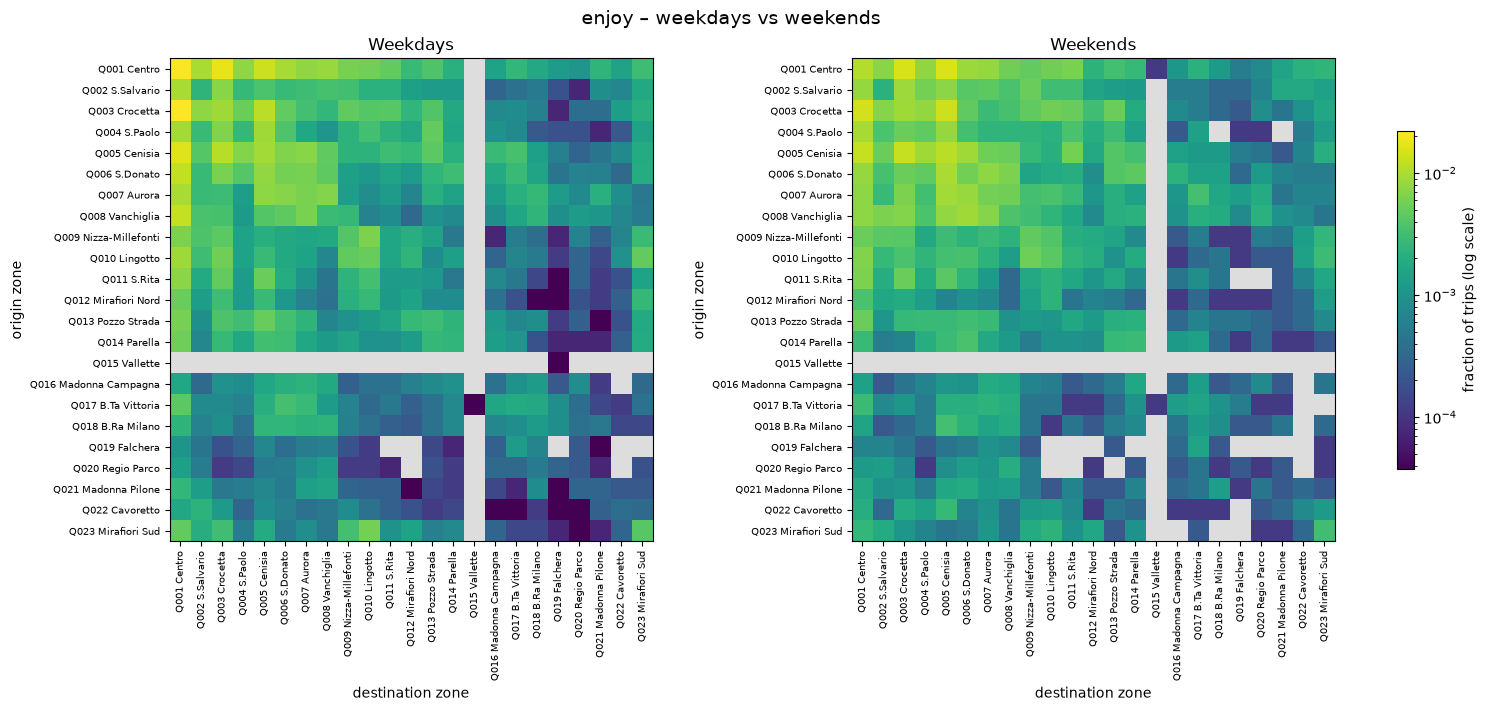

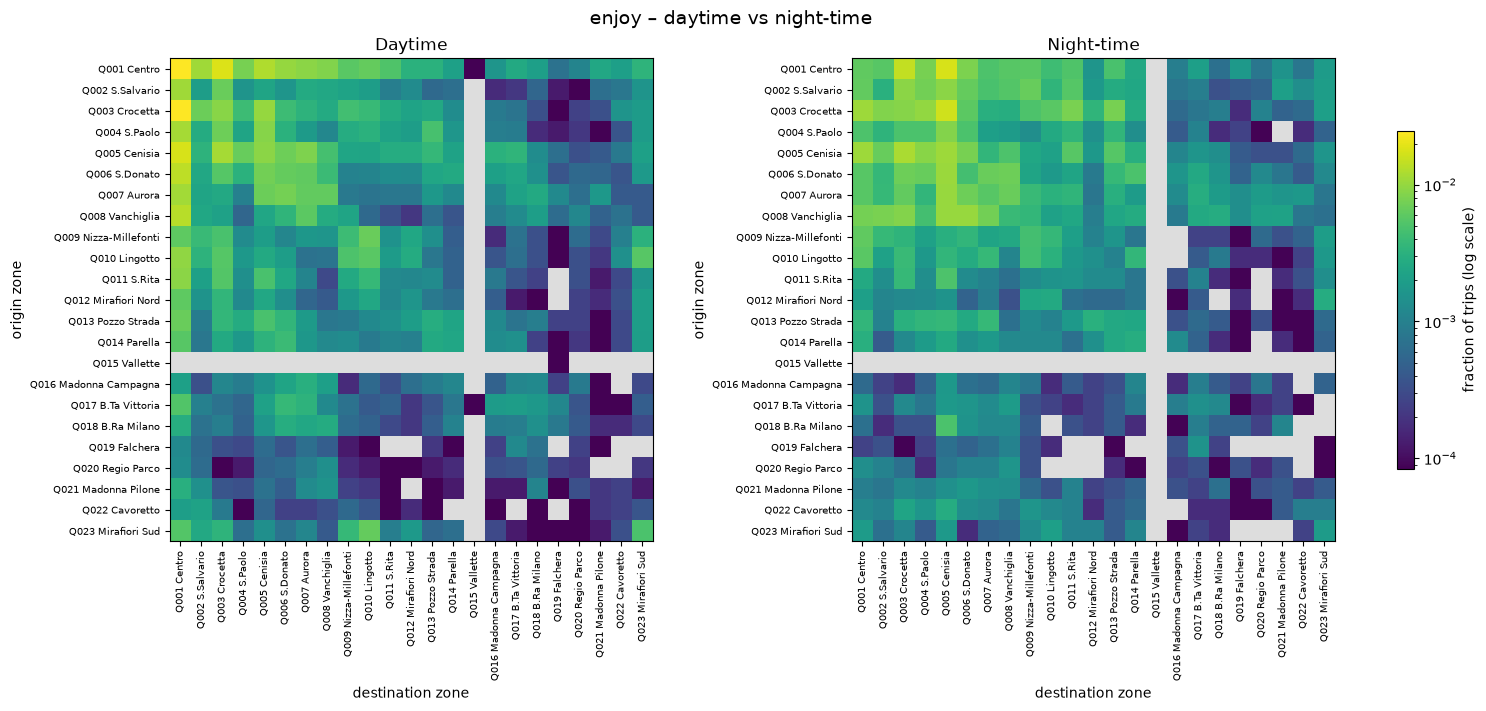

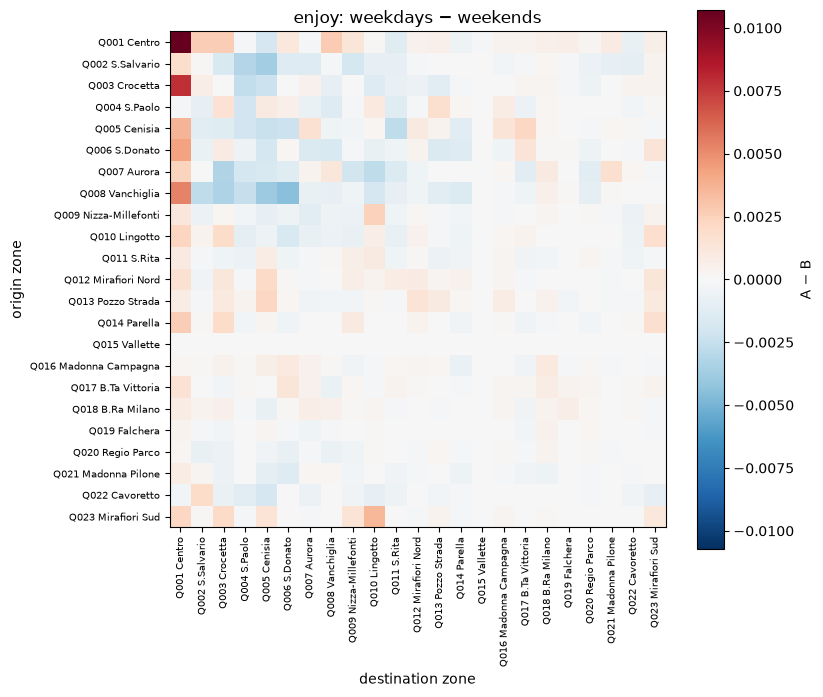

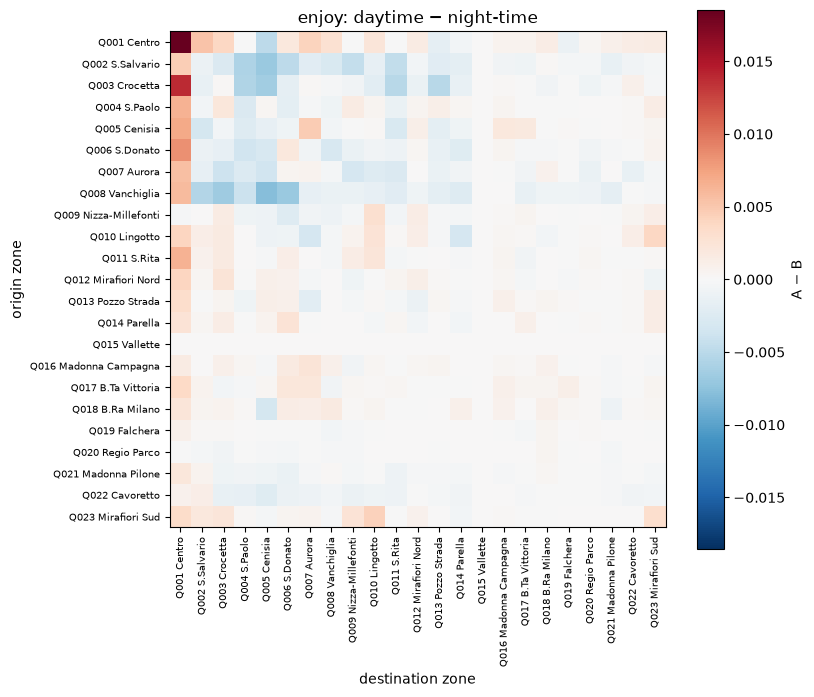

In [14]:
# heatmaps of each period and differences (red = more in the first period, blue = more in the second)
for vendor, P in od_periods.items():
    plot_heatmaps({'Weekdays': P['Weekdays'], 'Weekends': P['Weekends']},
                  f'{vendor} – weekdays vs weekends', f'task1a_{vendor}_week')
    plot_heatmaps({'Daytime': P['Daytime'], 'Night-time': P['Night-time']},
                  f'{vendor} – daytime vs night-time', f'task1a_{vendor}_day')
    plot_difference(P['Weekdays'], P['Weekends'], f'{vendor}: weekdays − weekends', f'task1a_{vendor}_diff_week')
    plot_difference(P['Daytime'], P['Night-time'], f'{vendor}: daytime − night-time', f'task1a_{vendor}_diff_day')

In [15]:
# how different (TVD) and where (OD pairs that change the most)
for vendor, P in od_periods.items():
    print(f"{vendor}: TVD weekdays vs weekends = {tvd(P['Weekdays'], P['Weekends']):.1f}%, "
          f"daytime vs night-time = {tvd(P['Daytime'], P['Night-time']):.1f}%")
    display(top_changes(P['Weekdays'], P['Weekends'], 'Weekdays', 'Weekends', n=5))
    display(top_changes(P['Daytime'], P['Night-time'], 'Daytime', 'Night-time', n=5))

car2go: TVD weekdays vs weekends = 16.9%, daytime vs night-time = 27.4%


,origin,destination,Weekdays (%),Weekends (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,4.01,2.22,1.79
1,Q003 Crocetta,Q001 Centro,3.32,1.95,1.37
2,Q001 Centro,Q003 Crocetta,2.53,1.88,0.65
3,Q005 Cenisia,Q001 Centro,2.20,1.58,0.62
4,Q006 S.Donato,Q001 Centro,1.69,1.20,0.49


,origin,destination,Daytime (%),Night-time (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,4.48,1.11,3.37
1,Q003 Crocetta,Q001 Centro,3.63,1.23,2.40
2,Q005 Cenisia,Q001 Centro,2.46,0.93,1.53
3,Q001 Centro,Q003 Crocetta,2.63,1.65,0.98
4,Q006 S.Donato,Q001 Centro,1.81,0.92,0.89


enjoy: TVD weekdays vs weekends = 16.2%, daytime vs night-time = 26.5%


,origin,destination,Weekdays (%),Weekends (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,2.14,1.07,1.07
1,Q003 Crocetta,Q001 Centro,2.22,1.43,0.78
2,Q008 Vanchiglia,Q001 Centro,1.28,0.75,0.53
3,Q008 Vanchiglia,Q006 S.Donato,0.45,0.90,-0.45
4,Q006 S.Donato,Q001 Centro,1.24,0.80,0.43


,origin,destination,Daytime (%),Night-time (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,2.47,0.62,1.85
1,Q003 Crocetta,Q001 Centro,2.47,1.09,1.39
2,Q006 S.Donato,Q001 Centro,1.40,0.56,0.84
3,Q008 Vanchiglia,Q005 Cenisia,0.24,1.03,-0.79
4,Q005 Cenisia,Q001 Centro,1.77,1.07,0.70


## Q1b – Same period, different dates
Weekday OD matrices of different calendar weeks. Since the share of rentals without a route changes from day
to day, a week is used only if every weekday has at least 50% of the typical daily number of trips.

In [16]:
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    print(vendor, '- weekday trips per calendar week (rows) and day (0 = Monday)')
    display(pd.crosstab(wd.week, wd.dow))

car2go - weekday trips per calendar week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
35,0,0,0,0,861
36,0,906,559,481,816
37,805,764,891,438,790
38,528,655,656,718,758
39,177,234,547,827,853
40,806,614,879,434,753
41,803,896,596,798,542
42,843,795,470,726,930
43,853,659,453,755,764


enjoy - weekday trips per calendar week (rows) and day (0 = Monday)


dow,0,1,2,3,4
week,,,,,
35,0,0,0,0,740
36,0,304,513,843,411
37,668,718,633,746,637
38,669,667,671,698,157
39,738,774,729,697,687
40,676,731,106,755,612
41,579,648,654,710,607
42,645,745,699,768,164
43,654,739,606,680,667


In [17]:
def full_weeks(df, min_share=0.5):
    """Weeks where every weekday has at least min_share of the typical (median) daily number of trips."""
    wd = select_period(df, days='weekdays')
    per_day = pd.crosstab(wd.week, wd.dow)
    typical = np.median(per_day.values[per_day.values > 0])
    return list(per_day.index[(per_day >= min_share * typical).all(axis=1)])

FULL_WEEKS = {vendor: full_weeks(df) for vendor, df in trips.items()}
print(FULL_WEEKS)
WEEK_A, WEEK_B = 41, 43     # must be in both lists above

{'car2go': [37, 38, 40, 41, 42, 43], 'enjoy': [37, 39, 41, 43]}


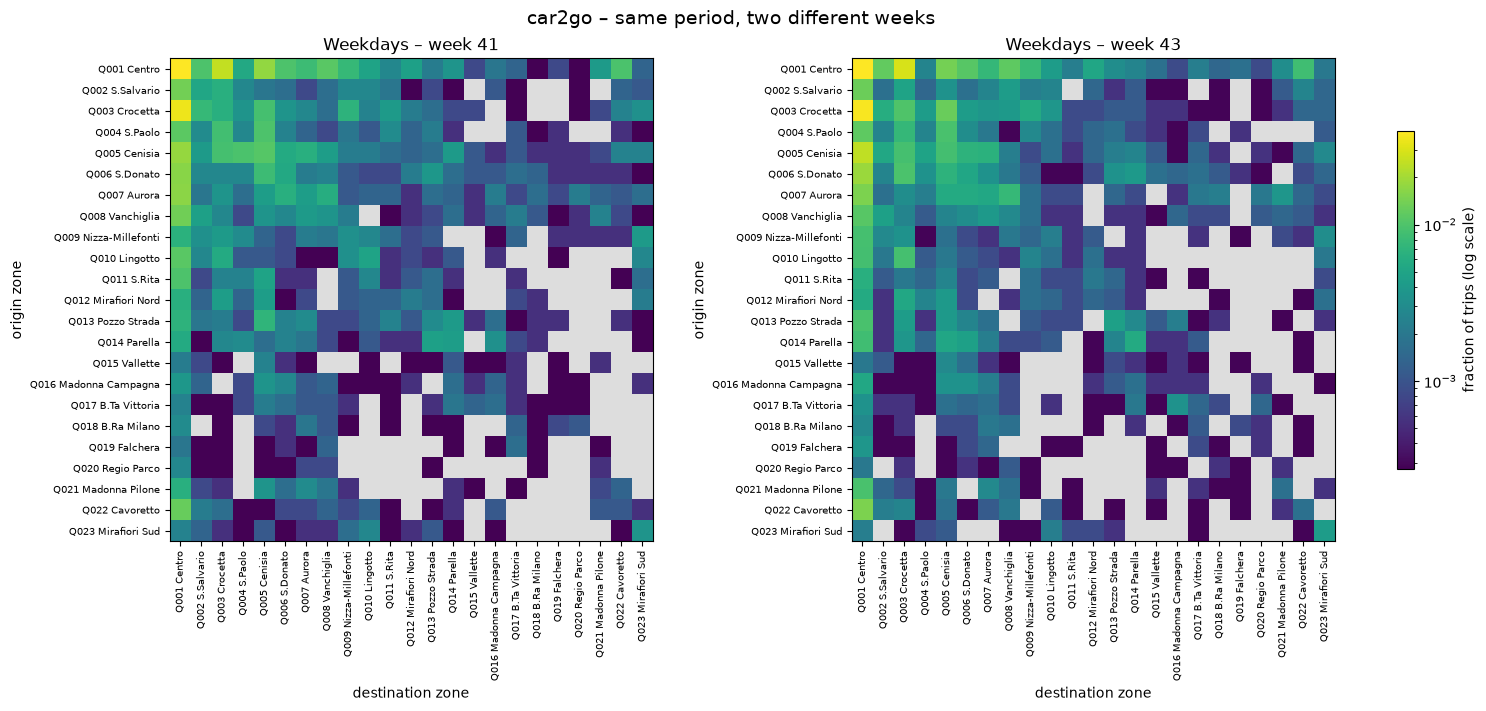

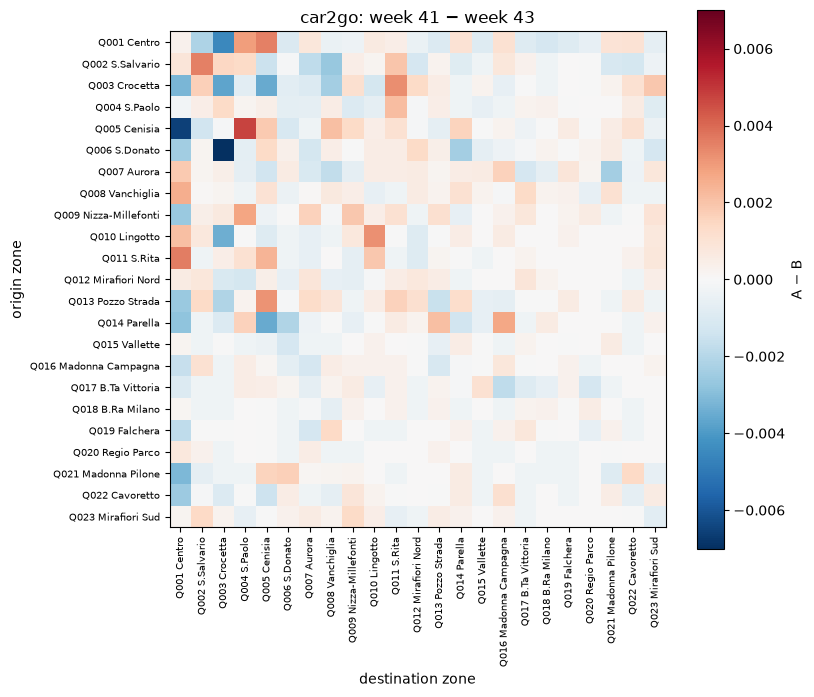

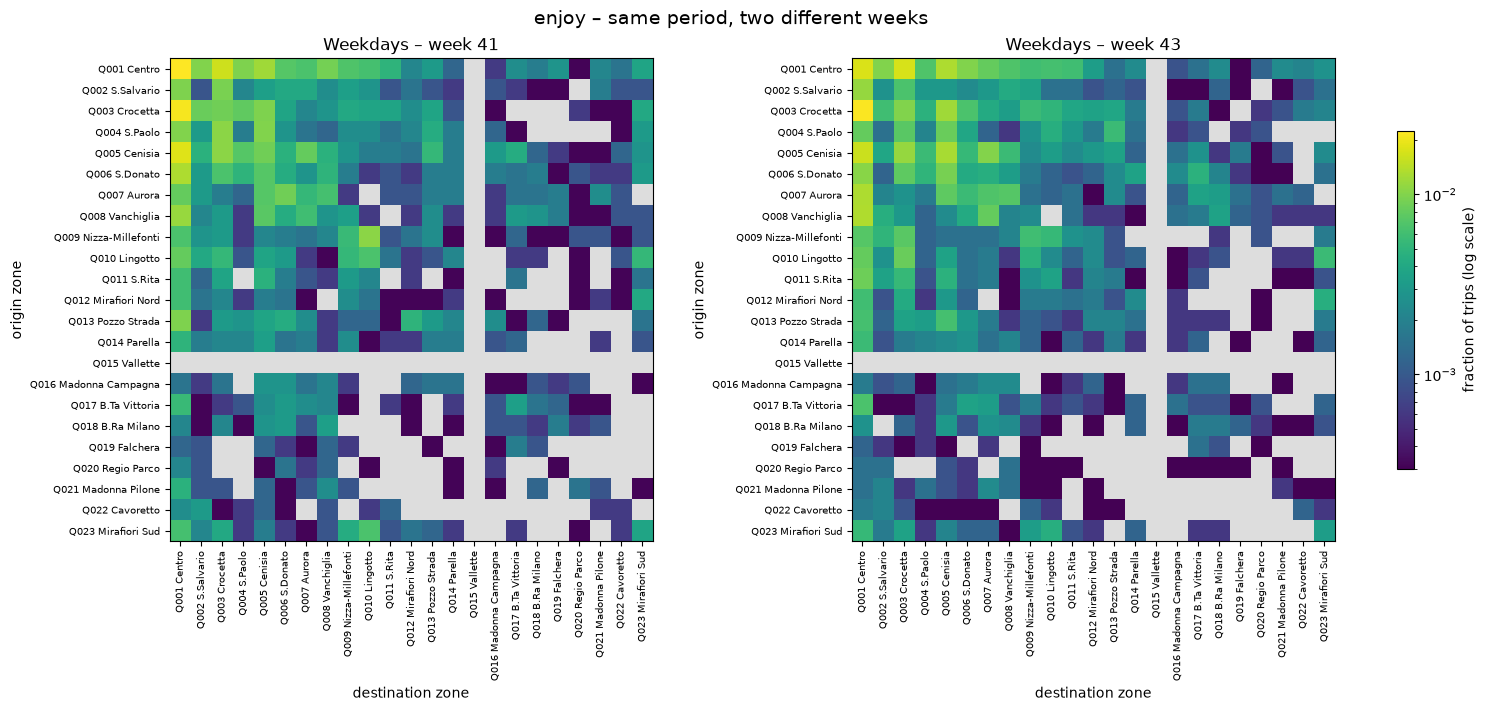

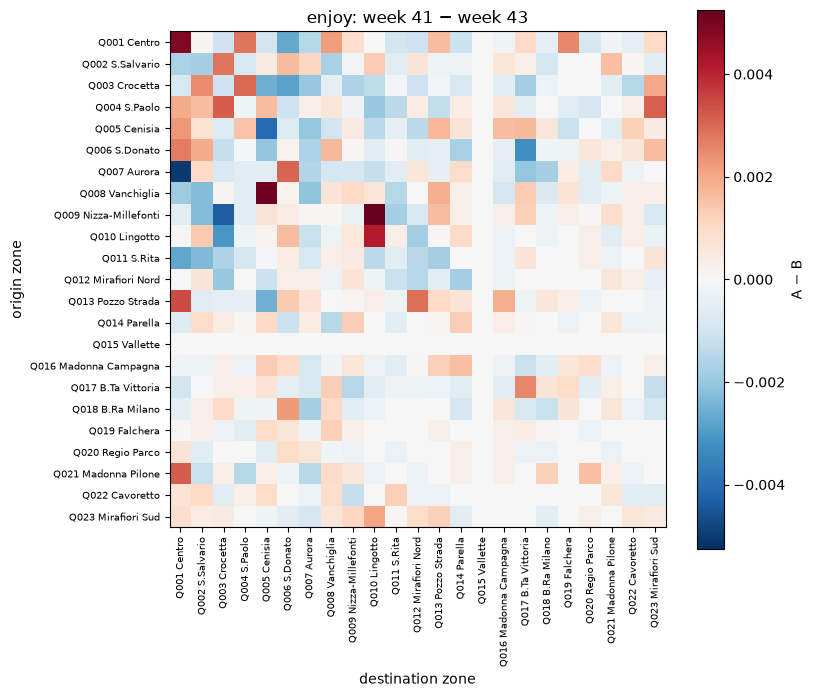

,count,mean,std,min,25%,50%,75%,max
vendor,,,,,,,,
car2go,15.0,18.180000,0.866190,16.4,17.65,18.40,18.65,19.9
enjoy,6.0,18.933333,1.136075,17.3,18.50,18.85,19.35,20.7


In [18]:
od_weeks = {}
for vendor, df in trips.items():
    wd = select_period(df, days='weekdays')
    od_weeks[vendor] = {w: od_matrix(wd[wd.week == w], ZONES) for w in FULL_WEEKS[vendor]}
    A, B = od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]
    plot_heatmaps({f'Weekdays – week {WEEK_A}': A, f'Weekdays – week {WEEK_B}': B},
                  f'{vendor} – same period, two different weeks', f'task1b_{vendor}_weeks')
    plot_difference(A, B, f'{vendor}: week {WEEK_A} − week {WEEK_B}', f'task1b_{vendor}_diff')

# TVD between all pairs of complete weeks
rows = [{'vendor': vendor, 'pair': f'{w1} vs {w2}', 'TVD (%)': tvd(mats[w1], mats[w2])}
        for vendor, mats in od_weeks.items() for w1, w2 in combinations(mats, 2)]
week_tvd = pd.DataFrame(rows).round(1)
week_tvd.groupby('vendor')['TVD (%)'].describe()

In [19]:
# reference for random noise: the same week split into two random halves
week = select_period(trips['car2go'], days='weekdays', weeks=[WEEK_A])
half1 = week.sample(frac=0.5, random_state=0)
half2 = week.drop(half1.index)
print(f'Car2Go week {WEEK_A}, two random halves: TVD = {tvd(od_matrix(half1, ZONES), od_matrix(half2, ZONES)):.1f}%')

Car2Go week 41, two random halves: TVD = 23.8%


In [20]:
# summary: different dates vs different periods
comparison = {}
for vendor, df in trips.items():
    week_a = select_period(df, weeks=[WEEK_A])
    P = od_periods[vendor]
    comparison[vendor] = {
        f'Weekdays: week {WEEK_A} vs {WEEK_B}':          tvd(od_weeks[vendor][WEEK_A], od_weeks[vendor][WEEK_B]),
        'Weekdays: all pairs of complete weeks (mean)': week_tvd[week_tvd.vendor == vendor]['TVD (%)'].mean(),
        f'Weekdays vs weekend, same week {WEEK_A}':       tvd(od_matrix(select_period(week_a, days='weekdays'), ZONES),
                                                           od_matrix(select_period(week_a, days='weekend'), ZONES)),
        'Weekdays vs weekends, all data':               tvd(P['Weekdays'], P['Weekends']),
        'Daytime vs night-time, all data':              tvd(P['Daytime'], P['Night-time']),
    }
comparison = pd.DataFrame(comparison).round(1)
comparison

,car2go,enjoy
Weekdays: week 41 vs 43,17.5,19.4
Weekdays: all pairs of complete weeks (mean),18.2,18.9
"Weekdays vs weekend, same week 41",29.8,30.9
"Weekdays vs weekends, all data",16.9,16.2
"Daytime vs night-time, all data",27.4,26.5


## Q1c – Same period and dates, Car2Go vs Enjoy
Weekdays of week WEEK_A for both platforms, then all dates in common.

59 common dates: 2017-09-01 -> 2017-10-31


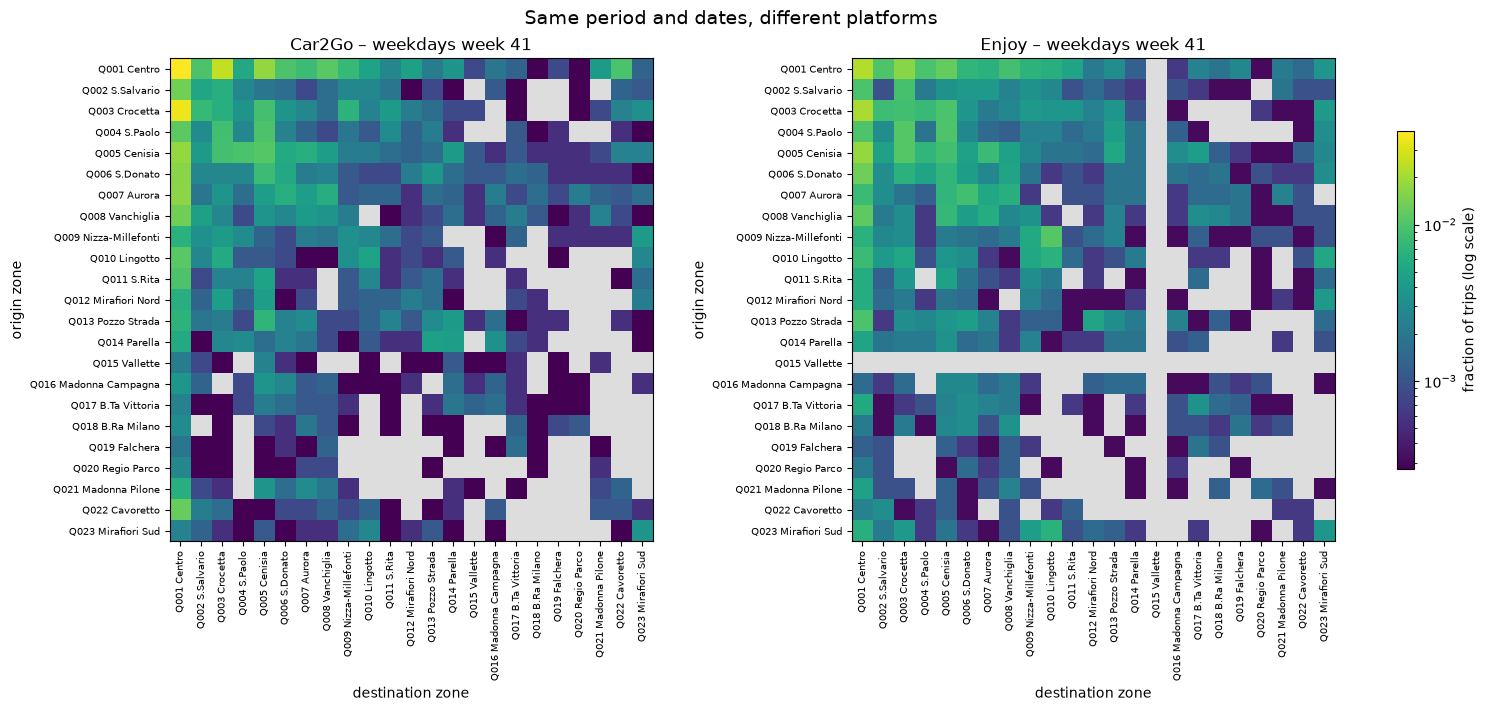

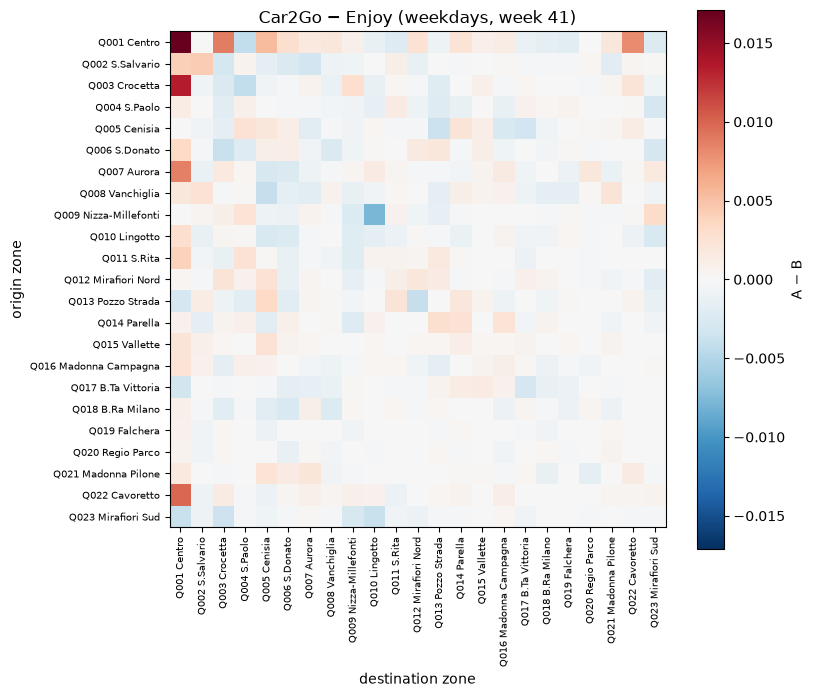

TVD Car2Go vs Enjoy, weekdays week 41: 26.1%
TVD Car2Go vs Enjoy, all common dates: 16.6%


In [21]:
common_dates = sorted(set(trips['car2go'].date) & set(trips['enjoy'].date))
same = {v: df[df.date.isin(common_dates)] for v, df in trips.items()}
print(f'{len(common_dates)} common dates: {common_dates[0]} -> {common_dates[-1]}')

od_vendor = {v: od_matrix(select_period(df, days='weekdays', weeks=[WEEK_A]), ZONES) for v, df in same.items()}
plot_heatmaps({f'Car2Go – weekdays week {WEEK_A}': od_vendor['car2go'],
               f'Enjoy – weekdays week {WEEK_A}': od_vendor['enjoy']},
              'Same period and dates, different platforms', 'task1c_heatmaps')
plot_difference(od_vendor['car2go'], od_vendor['enjoy'], f'Car2Go − Enjoy (weekdays, week {WEEK_A})', 'task1c_diff')

print(f"TVD Car2Go vs Enjoy, weekdays week {WEEK_A}: {tvd(od_vendor['car2go'], od_vendor['enjoy']):.1f}%")
print(f"TVD Car2Go vs Enjoy, all common dates: {tvd(od_matrix(same['car2go'], ZONES), od_matrix(same['enjoy'], ZONES)):.1f}%")

In [22]:
# share of trips starting (pO) and ending (pD) in each zone, and OD pairs that differ the most
od_same = {v: od_matrix(df, ZONES) for v, df in same.items()}
coverage = pd.DataFrame({
    'zone': zone_labels(ZONES),
    'Car2Go pO (%)': od_same['car2go'].sum(axis=1).values * 100,
    'Enjoy pO (%)':  od_same['enjoy'].sum(axis=1).values * 100,
    'Car2Go pD (%)': od_same['car2go'].sum(axis=0).values * 100,
    'Enjoy pD (%)':  od_same['enjoy'].sum(axis=0).values * 100,
})
coverage['diff pO (p.p.)'] = coverage['Car2Go pO (%)'] - coverage['Enjoy pO (%)']
display(coverage.round(2).sort_values('diff pO (p.p.)', ascending=False))
top_changes(od_vendor['car2go'], od_vendor['enjoy'], 'Car2Go', 'Enjoy')

,zone,Car2Go pO (%),Enjoy pO (%),Car2Go pD (%),Enjoy pD (%),diff pO (p.p.)
0,Q001 Centro,16.90,13.15,22.73,16.04,3.75
21,Q022 Cavoretto,2.88,1.27,2.12,1.11,1.61
14,Q015 Vallette,1.15,0.00,1.09,0.01,1.15
20,Q021 Madonna Pilone,2.33,1.34,1.43,1.01,0.98
13,Q014 Parella,3.64,3.30,3.26,2.79,0.33
2,Q003 Crocetta,9.51,9.39,9.58,9.61,0.13
1,Q002 S.Salvario,5.66,5.56,5.44,5.60,0.10
18,Q019 Falchera,0.75,0.73,0.64,0.76,0.03
6,Q007 Aurora,6.67,6.67,5.66,6.30,0.00
15,Q016 Madonna Campagna,1.82,1.85,1.73,1.73,-0.03


,origin,destination,Car2Go (%),Enjoy (%),difference (p.p.)
0,Q001 Centro,Q001 Centro,3.96,2.25,1.71
1,Q003 Crocetta,Q001 Centro,3.47,2.13,1.34
2,Q022 Cavoretto,Q001 Centro,1.24,0.25,0.99
3,Q001 Centro,Q003 Crocetta,2.50,1.63,0.88
4,Q007 Aurora,Q001 Centro,1.68,0.81,0.87
5,Q001 Centro,Q022 Cavoretto,0.96,0.16,0.81
6,Q009 Nizza-Millefonti,Q010 Lingotto,0.28,1.06,-0.79
7,Q001 Centro,Q005 Cenisia,1.76,1.22,0.54
8,Q002 S.Salvario,Q002 S.Salvario,0.52,0.09,0.43
9,Q003 Crocetta,Q004 S.Paolo,0.36,0.78,-0.42


# Q2

In [23]:

def js_divergence(P, Q):
    """Jensen-Shannon divergence (base 2); the square root is the distance."""
    P = np.asarray(P, dtype=float); Q = np.asarray(Q, dtype=float)
    P = P / P.sum(); Q = Q / Q.sum()          # safety normalization
    M = (P + Q) / 2
    kl = lambda x, y: np.sum(x[x > 0] * np.log2(x[x > 0] / y[x > 0]))
    return np.sqrt((kl(P, M) + kl(Q, M)) / 2)

# Q3 Compute OD matrices using UnipolTech dataset and IMQ dataset

### Loading IMQ Data

In [24]:
dfIMQ = pd.read_csv("./data/IMQ/IMQData_Torino.csv")
dfIMQ.head()

,ID_INT,GENDER,AGE,MOTIVATION,ORI_ZONE,DEP_HOUR,DST_ZONE,ARR_HOUR
0,8139335,1,2,5,Q005,02/02/17 10:00:00,Q023,02/02/17 10:20:00
1,8139641,2,4,4,Q002,02/02/17 16:30:00,Q023,02/02/17 16:50:00
2,8139830,1,2,4,Q019,02/02/17 14:30:00,Q019,02/02/17 14:50:00
3,8140616,1,2,9,Q003,02/02/17 20:00:00,Q005,02/02/17 20:30:00
4,8140678,2,3,4,Q009,02/02/17 09:00:00,Q009,02/02/17 09:10:00


In [25]:
def pct(OD):
    """Matrix normalization"""
    a = OD.to_numpy().astype(float)
    return 100 * a / max(a.sum(), 1)
def od_matrix(df, codes, origin="ORI_ZONE", dest="DST_ZONE", weight=None):
    """Matrice OD (comptages ou somme de poids), toutes zones conservées."""
    if weight is None:
        od = pd.crosstab(df[origin], df[dest])
    else:
        od = pd.crosstab(df[origin], df[dest], values=df[weight], aggfunc="sum").fillna(0)
    od = od.reindex(index=codes, columns=codes, fill_value=0)
    od.index.name, od.columns.name = "origin", "dest"
    return od

In [26]:
zones_raw = gpd.read_file("./data/IMQ/Zone/Zone_IMQ_TO_orig/Zone IMQ Prov_torino.shp", encoding="utf-8")
print("CRS d'origine :", zones_raw.crs)          # EPSG:23032 (ED50 / UTM 32N)

zones_imq = (
    zones_raw[zones_raw["Copia di C"].astype(str).str.match(r"^Q\d{3}$")]
    .rename(columns={"Copia di C": "zone_code"})[["zone_code", "zone_name", "geometry"]]
    .sort_values("zone_code")
    .reset_index(drop=True)
)
zones_imq["geometry"] = zones_imq.geometry.buffer(0)

zones_m = zones_imq.to_crs(32632)
zones_imq = zones_imq.to_crs(4326)
cent = zones_m.geometry.centroid.to_crs(4326)
zones_imq["cx"], zones_imq["cy"] = cent.x, cent.y
zones_imq["area_km2"] = (zones_m.area / 1e6).round(2)

codes = zones_imq["zone_code"].tolist()
print(len(zones_imq), "zones")
zones_imq.drop(columns="geometry").head()
OD_counts = od_matrix(dfIMQ, codes)                       
spost = pd.read_csv("./data/IMQ/IMQData/spostamentiTorino.csv", usecols=["TASSO_CAMP"])
assert len(spost) == len(dfIMQ)
dfIMQ["weight"] = spost["TASSO_CAMP"].values

CRS d'origine : EPSG:23032
23 zones


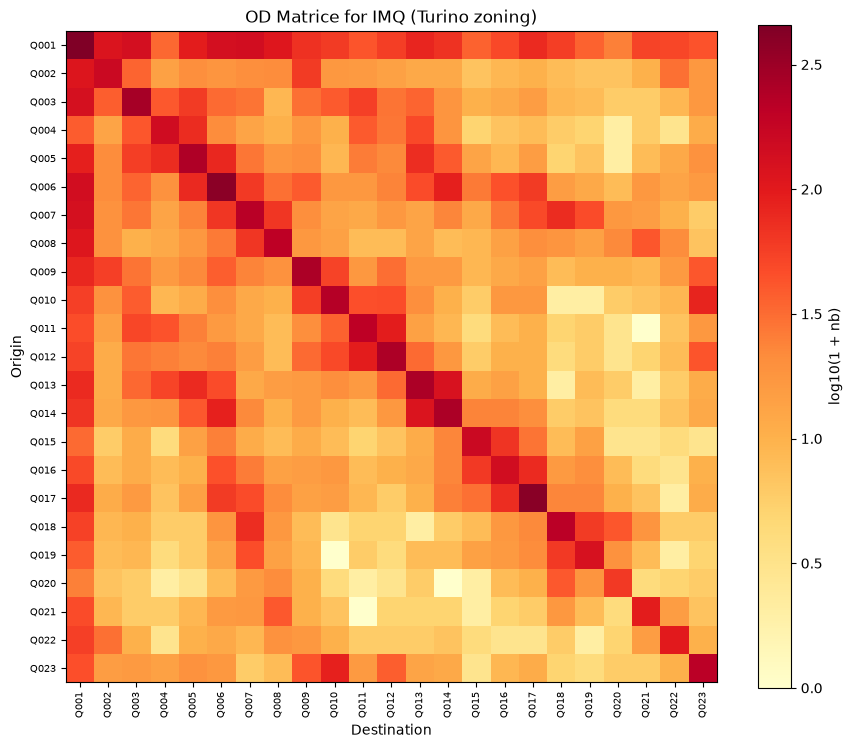

In [27]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.log10(OD_counts.to_numpy() + 1), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="log10(1 + nb)")
ax.set_title("OD Matrice for IMQ (Turino zoning)")
plt.tight_layout(); plt.show()

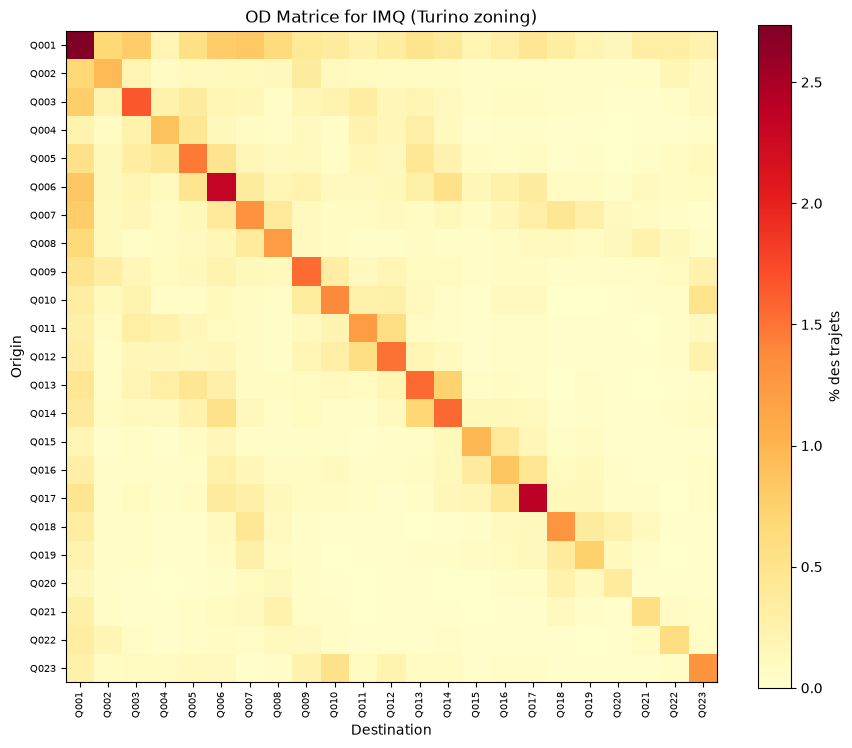

In [28]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(pct(OD_counts), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="% des trajets")
ax.set_title("OD Matrice for IMQ (Turino zoning)")
plt.tight_layout(); plt.show()

### Loading Unipol Data

In [29]:
UNI_DIR = "./data/Unipoldata"   
trips_raw = pd.read_csv(f"{UNI_DIR}/Trips_OD_TO.csv", parse_dates=["istante_start", "istante_stop"])
info = pd.read_csv(f"{UNI_DIR}/Info_TO.csv")

trips_raw = trips_raw.rename(columns={
    "lon_start": "origin_lon", "lat_start": "origin_lat",
    "lon_stop": "destination_lon", "lat_stop": "destination_lat",
    "istante_start": "init_date", "istante_stop": "final_date",
})
trips_raw["duration_min"] = (trips_raw["final_date"] - trips_raw["init_date"]).dt.total_seconds() / 60

trips_raw.head()
T_START, T_END = pd.Timestamp("2024-09-02"), pd.Timestamp("2024-09-09")     

trips_uni = trips_raw.merge(info, on="id_veicolo", how="left")

mask = (
    (trips_uni.init_date >= T_START) & (trips_uni.init_date < T_END)         
    & (trips_uni.duration_min > 0)                                                                                  
)
trips_uni = trips_uni[mask].reset_index(drop=True)

In [30]:
def assign_zones(pts, zones):
    """Code de zone IMQ pour chaque point (NaN si hors de Turin)."""
    j = gpd.sjoin(pts, zones[["zone_code", "geometry"]], how="left", predicate="intersects")
    j = j[~j.index.duplicated(keep="first")]   
    return j["zone_code"].reindex(pts.index)

origins = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_uni["origin_lon"], trips_uni["origin_lat"]), crs="EPSG:4326")
destinations = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_uni["destination_lon"], trips_uni["destination_lat"]), crs="EPSG:4326")

trips_uni["ORI_ZONE"] = assign_zones(origins, zones_imq).values
trips_uni["DST_ZONE"] = assign_zones(destinations, zones_imq).values

trips_z = trips_uni.dropna(subset=["ORI_ZONE", "DST_ZONE"])
OD_uni = od_matrix(trips_z, codes)

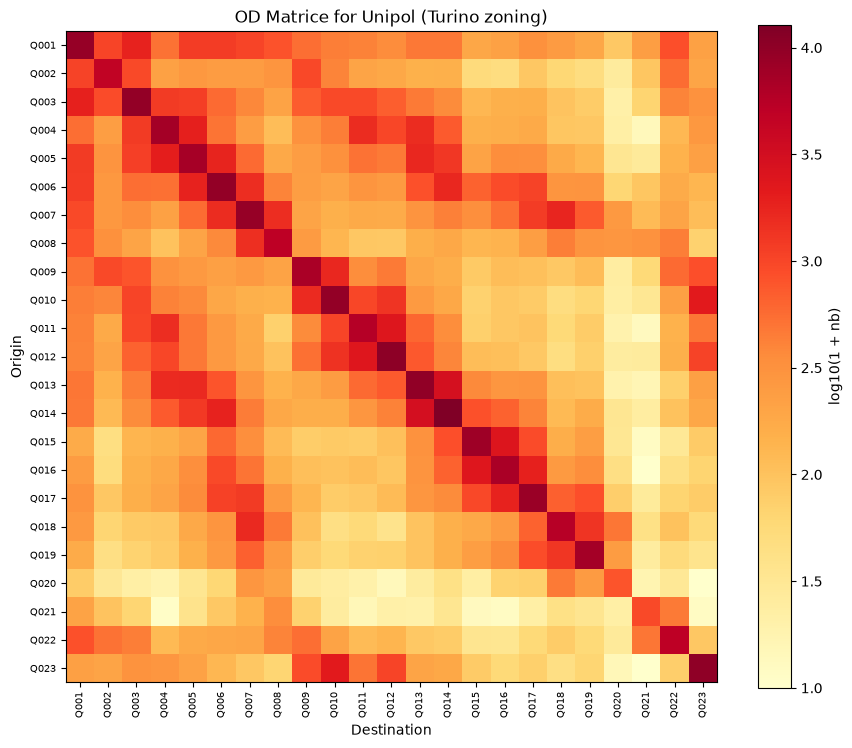

In [31]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(np.log10(OD_uni.to_numpy() + 1), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="log10(1 + nb)")
ax.set_title("OD Matrice for Unipol (Turino zoning)")
plt.tight_layout(); plt.show()

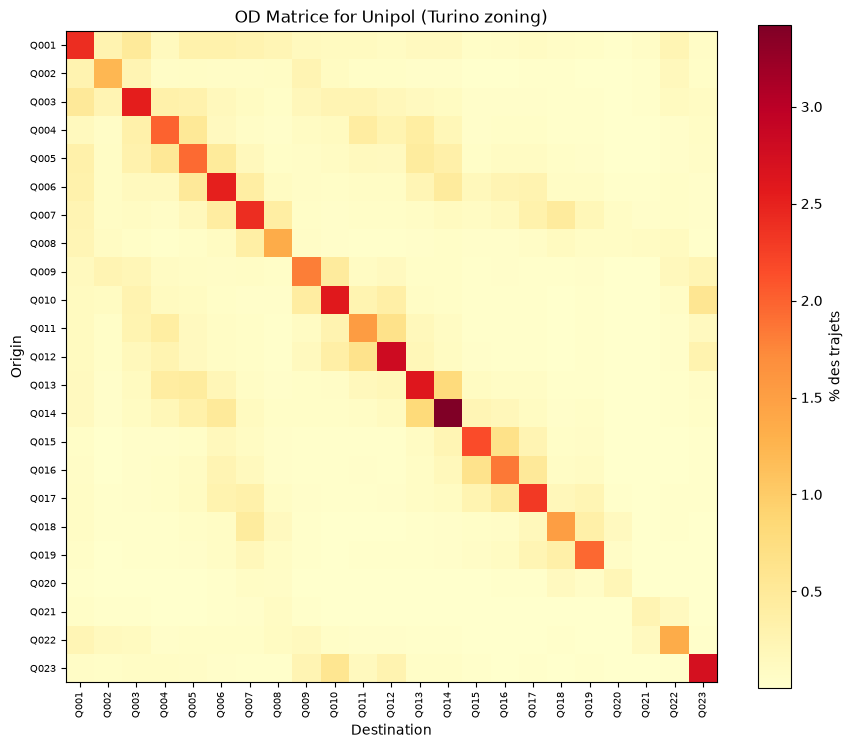

In [32]:
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(pct(OD_uni), cmap="YlOrRd")
ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=7)
ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=7)
ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
fig.colorbar(im, label="% des trajets")
ax.set_title("OD Matrice for Unipol (Turino zoning)")
plt.tight_layout(); plt.show()

### Raw Comparison

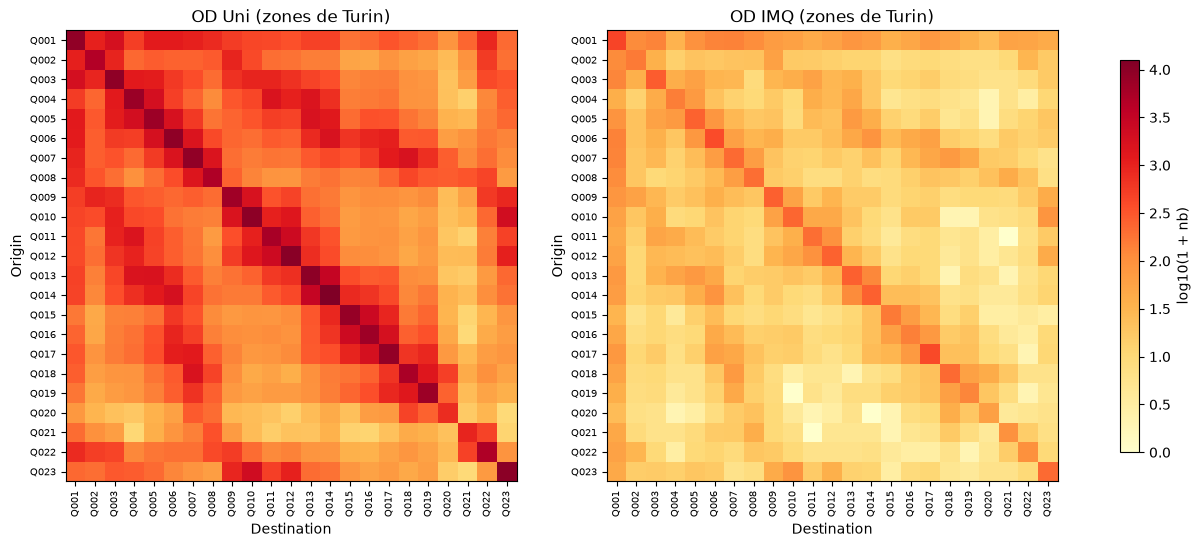

In [33]:
vmax_log = np.log10(max(OD_uni.to_numpy().max(), OD_counts.to_numpy().max()) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))

for ax, (name, M) in zip(axes, [("OD Uni", OD_uni), ("OD IMQ", OD_counts)]):
    im = ax.imshow(np.log10(M.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax_log)
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(M.index)));  ax.set_yticklabels(M.index, fontsize=7)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
    ax.set_title(f"{name} (zones de Turin)")

fig.colorbar(im, ax=axes, shrink=0.75, label="log10(1 + nb)")
plt.show()

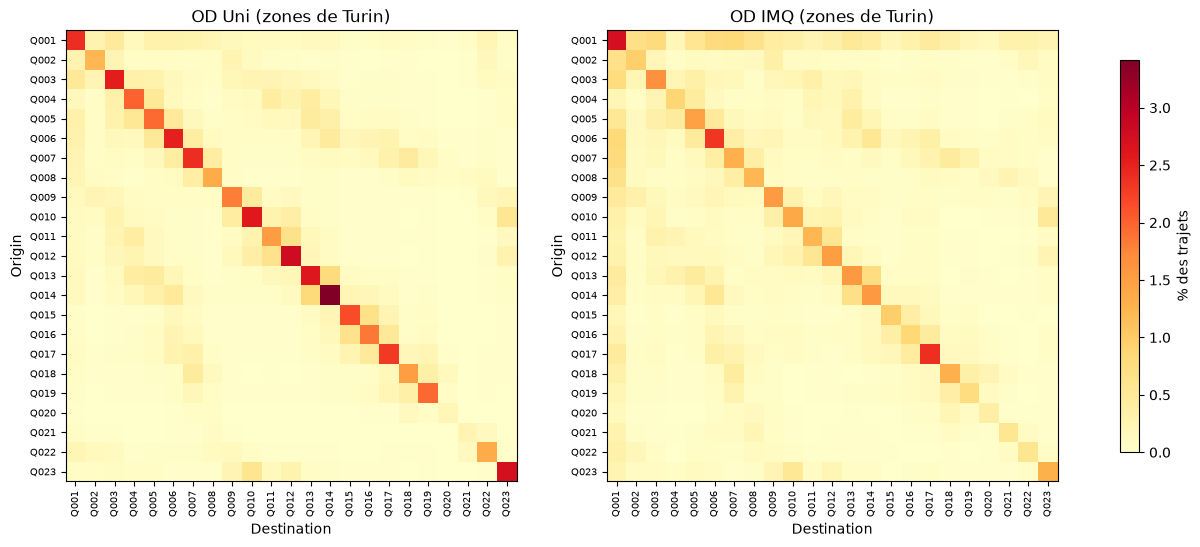

In [34]:
vmax = max(pct(OD_uni).max(), pct(OD_counts).max())

fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))

for ax, (name, M) in zip(axes, [("OD Uni", OD_uni), ("OD IMQ", OD_counts)]):
    im = ax.imshow(pct(M), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(M.columns))); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(M.index)));  ax.set_yticklabels(M.index, fontsize=7)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
    ax.set_title(f"{name} (zones de Turin)")

fig.colorbar(im, ax=axes, shrink=0.75, label="% des trajets")
plt.show()

## Q3.a 

In [35]:
def _sjoin_zone(pts, zones):
    """Jointure spatiale : point à l'intérieur d'une zone -> zone_code (NaN sinon)."""
    j = gpd.sjoin(pts, zones[["zone_code", "geometry"]], how="left", predicate="within")
    j = j[~j.index.duplicated(keep="first")]          # un seul match par point
    return j["zone_code"].reindex(pts.index)


def _nearest_zone(pts_missing, zones):
    """Fallback : zone IMQ la plus proche (distances en projection métrique EPSG:32632)."""
    zp = zones.to_crs(32632)
    pm = pts_missing.to_crs(32632)
    j = gpd.sjoin_nearest(pm, zp[["zone_code", "geometry"]], how="left")
    j = j[~j.index.duplicated(keep="first")]
    return j["zone_code"].reindex(pts_missing.index)


def assign_imq_zones(df, zones, fallback="nearest",
                     lon_o="origin_lon", lat_o="origin_lat",
                     lon_d="destination_lon", lat_d="destination_lat"):
    """Ajoute les colonnes ORI_ZONE / DST_ZONE (codes IMQ) à un DataFrame de trajets."""
    d = df.copy()
    for prefix, lo, la in [("ORI", lon_o, lat_o), ("DST", lon_d, lat_d)]:
        pts = gpd.GeoDataFrame(
            geometry=gpd.points_from_xy(d[lo], d[la]),
            crs="EPSG:4326", index=d.index,
        )
        zone = _sjoin_zone(pts, zones)
        n_out = int(zone.isna().sum())
        if n_out and fallback == "nearest":
            zone.loc[zone.isna()] = _nearest_zone(pts[zone.isna()], zones)
            # print(f"{prefix} : {n_out} points hors des {len(zones)} zones IMQ -> zone la plus proche")
        else:
            pass
            # print(f"{prefix} : {n_out} points hors des {len(zones)} zones IMQ (NaN conservés)")
        d[f"{prefix}_ZONE"] = zone.to_numpy()
    return d

trips_uni_z = assign_imq_zones(trips_uni, zones_imq)   # Unipol filtré (cellule 26)


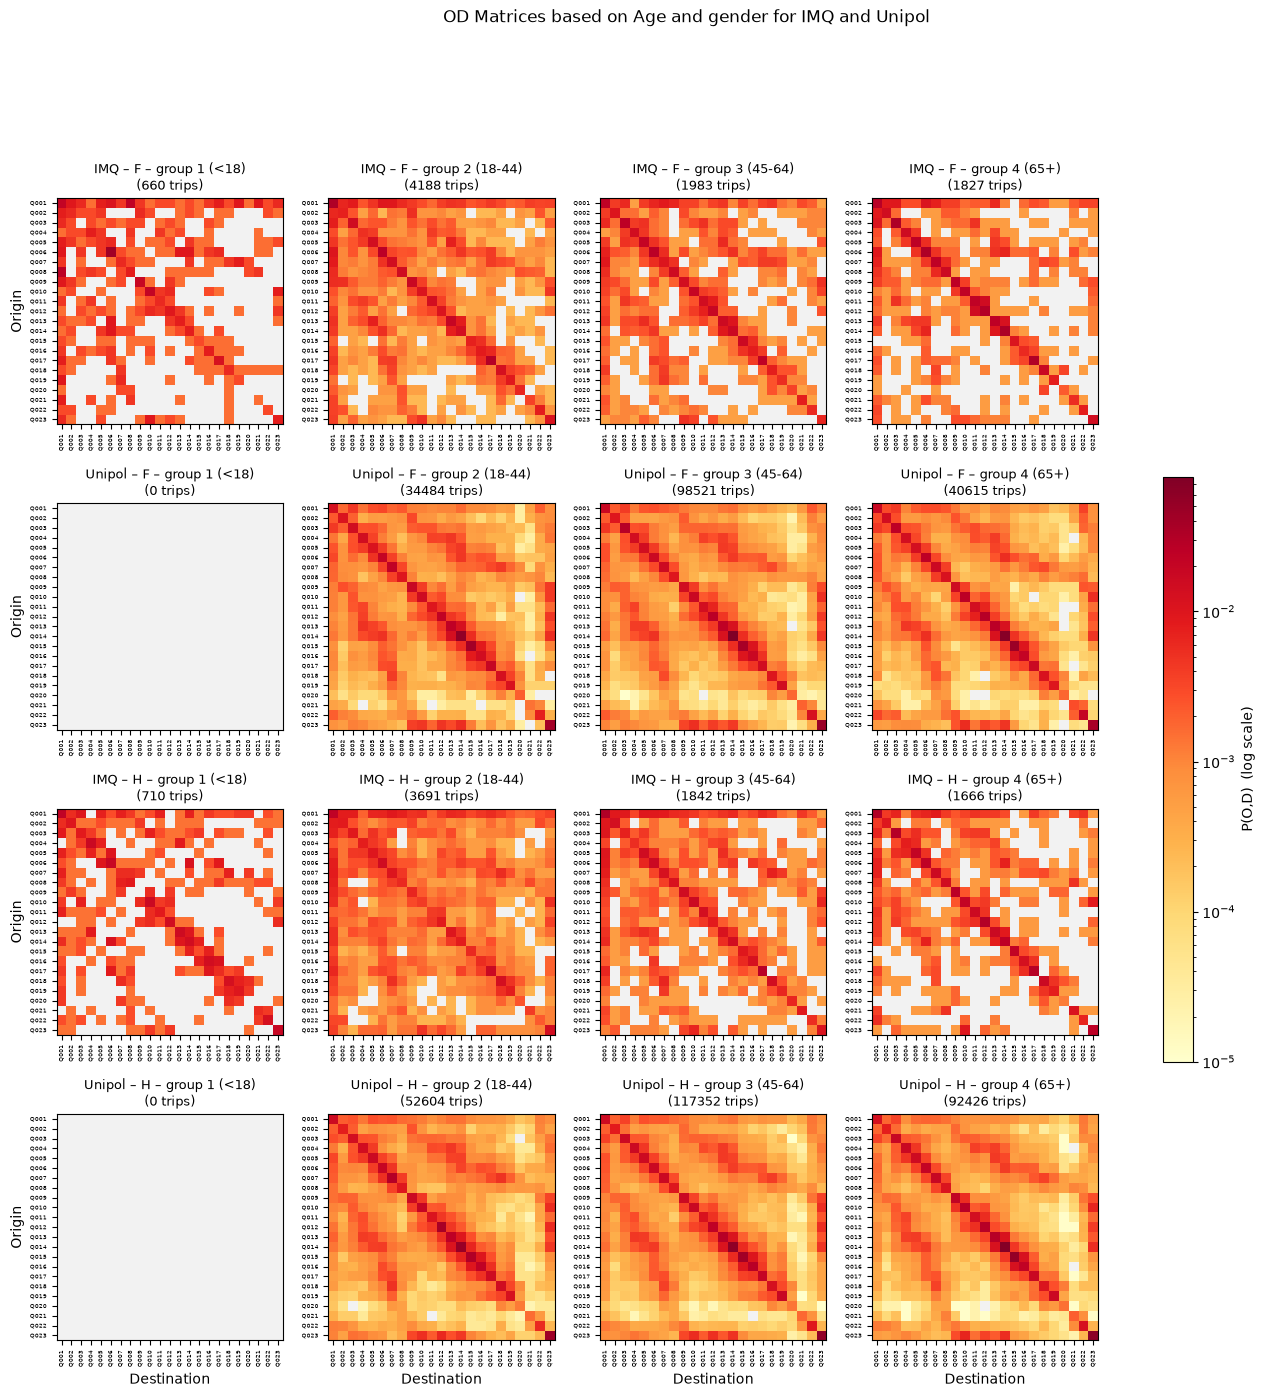

Jensen-Shannon distance IMQ and Unipol :


,group 1 (<18),group 2 (18-44),group 3 (45-64),group 4 (65+)
F,NaN,0.2896,0.2966,0.2948
H,NaN,0.3330,0.3290,0.2998


,IMQ,Unipol
group 1 (<18),0.083,0.000
group 2 (18-44),0.476,0.200
group 3 (45-64),0.231,0.495
group 4 (65+),0.211,0.305


In [36]:
AGE_BINS  = [0, 18, 45, 65, 120]     
AGE_LABEL = {1: "group 1 (<18)", 2: "group 2 (18-44)", 3: "group 3 (45-64)", 4: "group 4 (65+)"}
SEX_IMQ   = {1: "H", 2: "F"}           
SEX_UNI   = {"M": "H", "F": "F"}        

imq = dfIMQ.assign(sexe=dfIMQ["GENDER"].map(SEX_IMQ), age_cl=dfIMQ["AGE"]).dropna(subset=["sexe", "age_cl"])
imq["age_cl"] = imq["age_cl"].astype(int)

uni = trips_uni_z[(trips_uni_z["commerciale"] == "N") & trips_uni_z["genere"].isin(SEX_UNI)]
uni = uni.dropna(subset=["ORI_ZONE", "DST_ZONE", "eta_approx"]).copy()
uni["sexe"]   = uni["genere"].map(SEX_UNI)
uni["age_cl"] = pd.cut(uni["eta_approx"], AGE_BINS, labels=[1, 2, 3, 4], right=False).astype(int)

sexes, ages = ["F", "H"], [1, 2, 3, 4]
P, N = {}, {}
for src, df in [("IMQ", imq), ("Unipol", uni)]:
    for s in sexes:
        for a in ages:
            M = od_matrix(df[(df["sexe"] == s) & (df["age_cl"] == a)], codes).to_numpy(float)
            N[(src, s, a)] = int(M.sum())
            P[(src, s, a)] = M / M.sum() if M.sum() > 0 else M

rows = [(s, src) for s in sexes for src in ["IMQ", "Unipol"]]
vmax = max(m.max() for m in P.values())
cmap = plt.get_cmap("YlOrRd").copy(); cmap.set_bad("#f2f2f2")      

fig, axes = plt.subplots(len(rows), len(ages), figsize=(4.2 * len(ages), 3.8 * len(rows)), squeeze=False)
for i, (s, src) in enumerate(rows):
    for j, a in enumerate(ages):
        ax = axes[i][j]
        im = ax.imshow(P[(src, s, a)], cmap=cmap, norm=LogNorm(vmin=1e-5, vmax=vmax))
        ax.set_title(f"{src} – {s} – {AGE_LABEL[a]}\n({N[(src, s, a)]} trips)", fontsize=9)
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=4)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=4)
        if i == len(rows) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.5, label="P(O,D)  (log scale)")
fig.suptitle("OD Matrices based on Age and gender for IMQ and Unipol", y=0.995)
plt.show()

js = pd.DataFrame(
    {AGE_LABEL[a]: {s: (jensenshannon(P[("IMQ", s, a)].ravel(), P[("Unipol", s, a)].ravel())
                        if N[("IMQ", s, a)] and N[("Unipol", s, a)] else np.nan)
                    for s in sexes} for a in ages}
).round(4)
print("Jensen-Shannon distance IMQ and Unipol :")
display(js)

part = pd.DataFrame({src: {AGE_LABEL[a]: sum(N[(src, s, a)] for s in sexes) for a in ages}
                     for src in ["IMQ", "Unipol"]})
display((part / part.sum()).round(3))

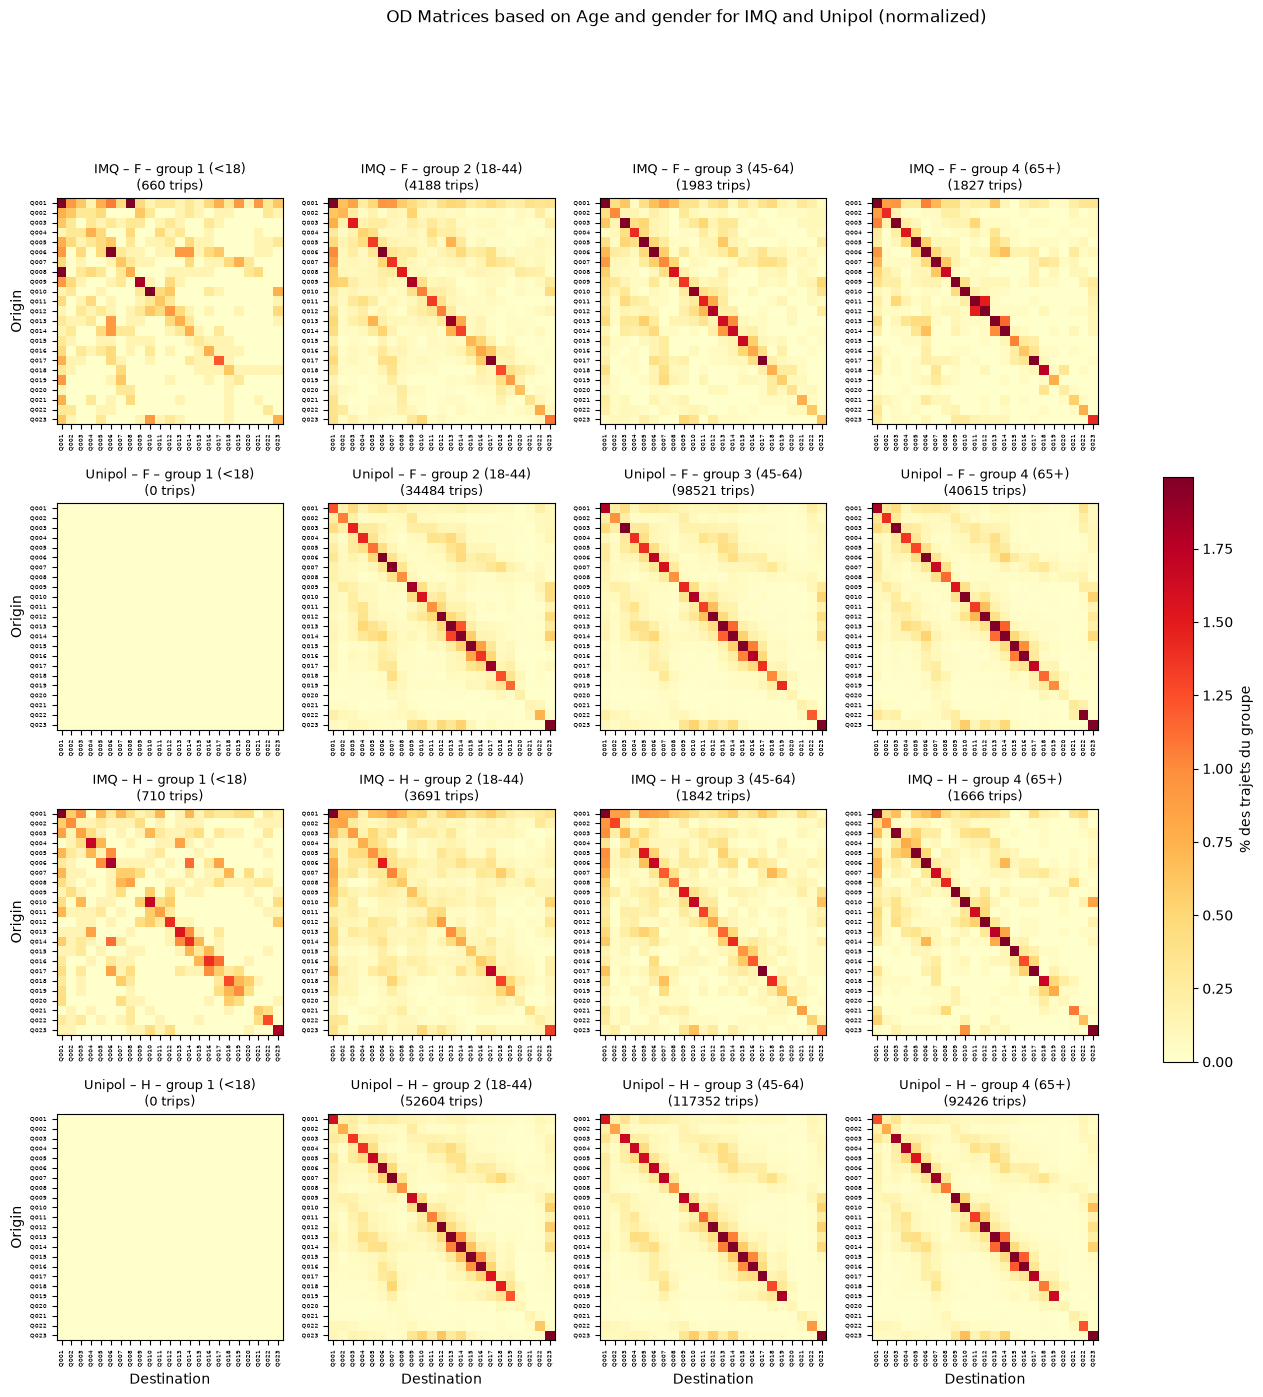

Jensen-Shannon distance IMQ and Unipol :


,group 1 (<18),group 2 (18-44),group 3 (45-64),group 4 (65+)
F,NaN,0.2896,0.2966,0.2948
H,NaN,0.3330,0.3290,0.2998


,IMQ,Unipol
group 1 (<18),0.083,0.000
group 2 (18-44),0.476,0.200
group 3 (45-64),0.231,0.495
group 4 (65+),0.211,0.305


In [37]:

AGE_BINS  = [0, 18, 45, 65, 120]
AGE_LABEL = {1: "group 1 (<18)", 2: "group 2 (18-44)", 3: "group 3 (45-64)", 4: "group 4 (65+)"}
SEX_IMQ   = {1: "H", 2: "F"}
SEX_UNI   = {"M": "H", "F": "F"}

imq = dfIMQ.assign(sexe=dfIMQ["GENDER"].map(SEX_IMQ), age_cl=dfIMQ["AGE"]).dropna(subset=["sexe", "age_cl"])
imq["age_cl"] = imq["age_cl"].astype(int)

uni = trips_uni_z[(trips_uni_z["commerciale"] == "N") & trips_uni_z["genere"].isin(SEX_UNI)]
uni = uni.dropna(subset=["ORI_ZONE", "DST_ZONE", "eta_approx"]).copy()
uni["sexe"]   = uni["genere"].map(SEX_UNI)
uni["age_cl"] = pd.cut(uni["eta_approx"], AGE_BINS, labels=[1, 2, 3, 4], right=False).astype(int)

sexes, ages = ["F", "H"], [1, 2, 3, 4]
P, N = {}, {}
for src, df in [("IMQ", imq), ("Unipol", uni)]:
    for s in sexes:
        for a in ages:
            M = od_matrix(df[(df["sexe"] == s) & (df["age_cl"] == a)], codes).to_numpy(float)
            N[(src, s, a)] = int(M.sum())
            P[(src, s, a)] = M / M.sum() if M.sum() > 0 else M    # somme = 1

rows = [(s, src) for s in sexes for src in ["IMQ", "Unipol"]]
vmax = 100 * np.percentile(np.concatenate([m.ravel() for m in P.values()]), 99)

fig, axes = plt.subplots(len(rows), len(ages), figsize=(4.2 * len(ages), 3.8 * len(rows)), squeeze=False)
for i, (s, src) in enumerate(rows):
    for j, a in enumerate(ages):
        ax = axes[i][j]
        im = ax.imshow(100 * P[(src, s, a)], cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{src} – {s} – {AGE_LABEL[a]}\n({N[(src, s, a)]} trips)", fontsize=9)
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=4)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=4)
        if i == len(rows) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.5, label="% des trajets du groupe")
fig.suptitle("OD Matrices based on Age and gender for IMQ and Unipol (normalized)", y=0.995)
plt.show()

js = pd.DataFrame(
    {AGE_LABEL[a]: {s: (jensenshannon(P[("IMQ", s, a)].ravel(), P[("Unipol", s, a)].ravel())
                        if N[("IMQ", s, a)] and N[("Unipol", s, a)] else np.nan)
                    for s in sexes} for a in ages}
).round(4)
print("Jensen-Shannon distance IMQ and Unipol :")
display(js)

part = pd.DataFrame({src: {AGE_LABEL[a]: sum(N[(src, s, a)] for s in sexes) for a in ages}
                     for src in ["IMQ", "Unipol"]})
display((part / part.sum()).round(3))

# List of Motivation
1. Go to work 
2. Working Reason
3. Study
4. Shopping
5. Bring Someone
6. Cures/Medical Visits
7. Sport or Leisure
8. Going back home
9. Visiting Relatives
10. Other
11. Going back home on the day of the Interview

Motivations présentes : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | n trajets par motif : {1: 2203, 2: 348, 3: 569, 4: 2635, 5: 759, 6: 405, 7: 1442, 8: 7551, 9: 510, 10: 23, 11: 122}


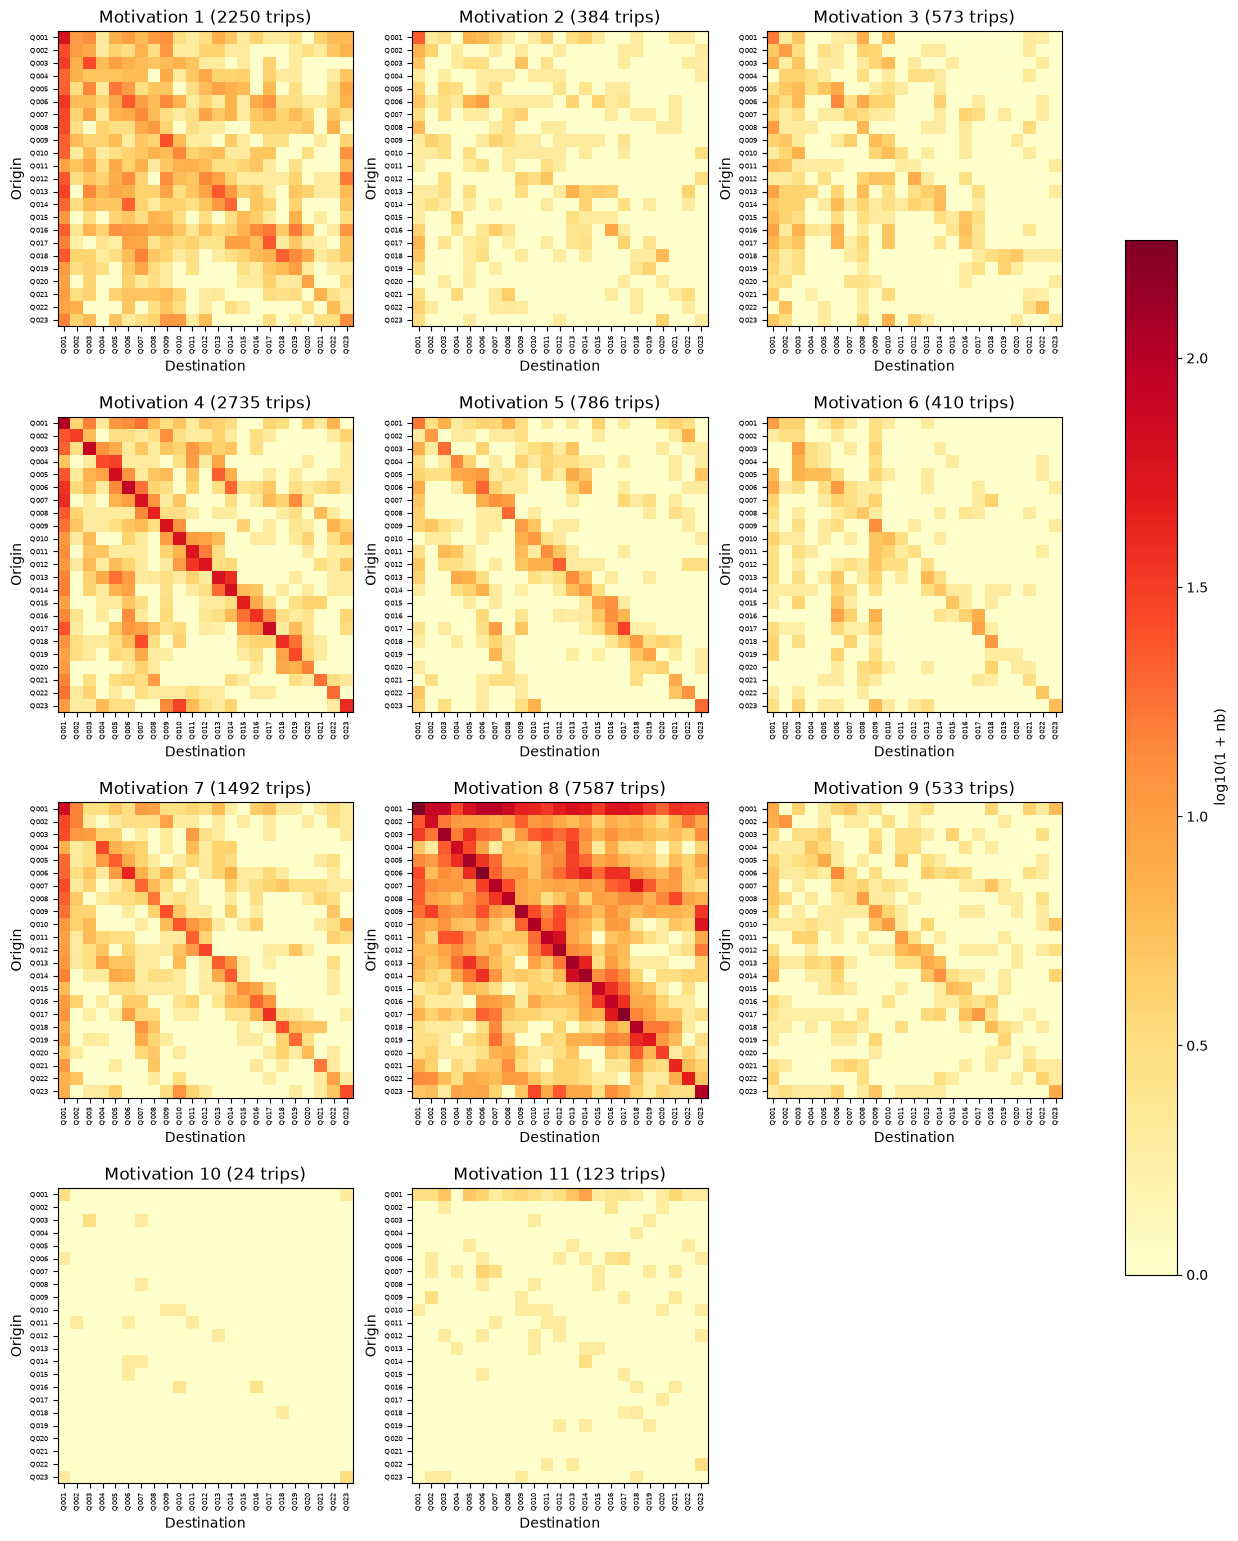

In [38]:
# OD Based on Motivation
motifs = sorted(dfIMQ["MOTIVATION"].dropna().astype(int).unique())
print("Motivations présentes :", motifs, "| n trajets par motif :",
      dfIMQ["MOTIVATION"].value_counts().reindex(motifs).to_dict())

OD_motif = {
    m: od_matrix(dfIMQ[dfIMQ["MOTIVATION"] == m], codes, weight="weight")
    for m in motifs
}

# affichage : une heatmap par motivation, échelle log commune
ncols, nrows = 3, int(np.ceil(len(motifs) / 3))
vmax = np.log10(max(OD.to_numpy().max() for OD in OD_motif.values()) + 1)

fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.8 * nrows), squeeze=False)
for k, m in enumerate(motifs):
    ax, OD = axes[k // ncols][k % ncols], OD_motif[m]
    im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_title(f"Motivation {m} ({OD.to_numpy().sum():.0f} trips)")
    ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
    ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
for k in range(len(motifs), nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="log10(1 + nb)")
plt.show()

Motivations présentes : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11)] | n trajets par motif : {1: 2203, 2: 348, 3: 569, 4: 2635, 5: 759, 6: 405, 7: 1442, 8: 7551, 9: 510, 10: 23, 11: 122}


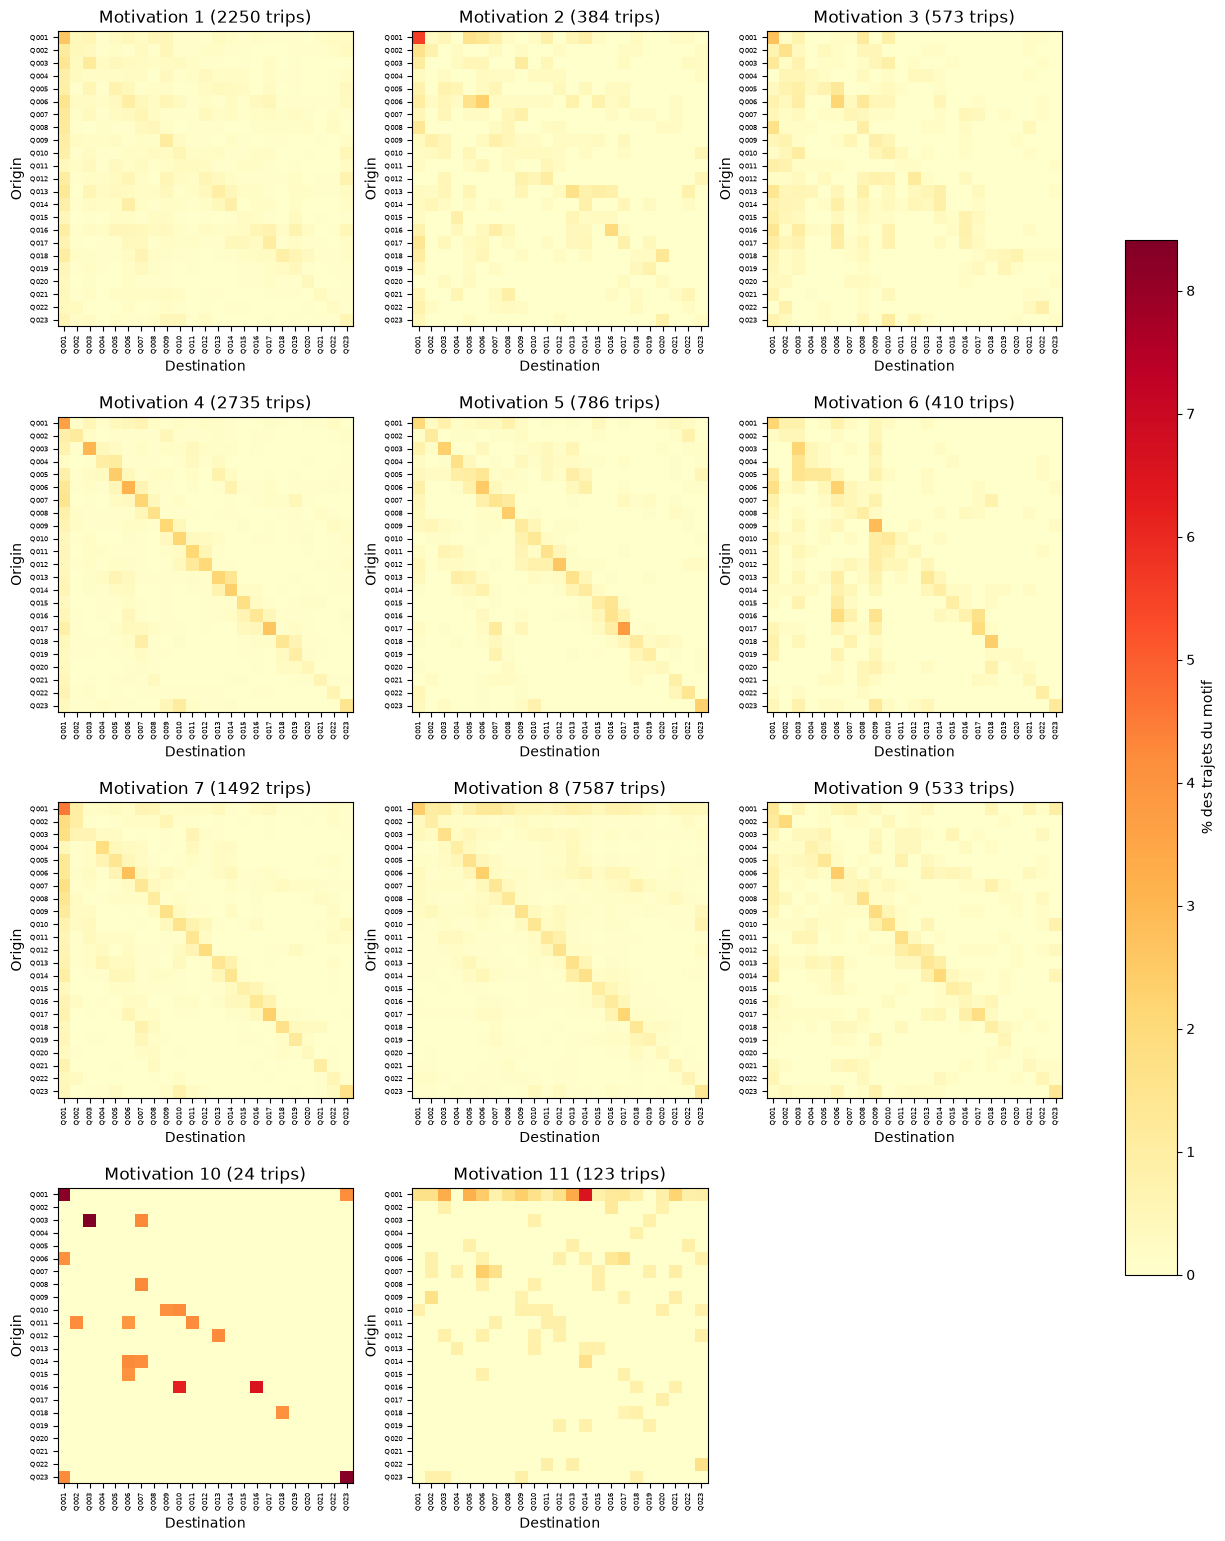

In [39]:
# OD Based on Motivation
motifs = sorted(dfIMQ["MOTIVATION"].dropna().astype(int).unique())
print("Motivations présentes :", motifs, "| n trajets par motif :",
      dfIMQ["MOTIVATION"].value_counts().reindex(motifs).to_dict())

OD_motif = {
    m: od_matrix(dfIMQ[dfIMQ["MOTIVATION"] == m], codes, weight="weight")
    for m in motifs
}

ncols, nrows = 3, int(np.ceil(len(motifs) / 3))
vmax = max(pct(OD).max() for OD in OD_motif.values())

fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 4.8 * nrows), squeeze=False)
for k, m in enumerate(motifs):
    ax, OD = axes[k // ncols][k % ncols], OD_motif[m]
    im = ax.imshow(pct(OD), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_title(f"Motivation {m} ({OD.to_numpy().sum():.0f} trips)")
    ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
    ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
    ax.set_xlabel("Destination"); ax.set_ylabel("Origin")
for k in range(len(motifs), nrows * ncols):
    axes[k // ncols][k % ncols].axis("off")
fig.colorbar(im, ax=axes, shrink=0.7, label="% des trajets du motif")
plt.show()

## Q3.b

Sex : [np.int64(1), np.int64(2)] | Age : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
sex 1 x age 1 : 710 trips (4.3%)
sex 1 x age 2 : 3691 trips (22.3%)
sex 1 x age 3 : 1842 trips (11.1%)
sex 1 x age 4 : 1666 trips (10.1%)
sex 2 x age 1 : 660 trips (4.0%)
sex 2 x age 2 : 4188 trips (25.3%)
sex 2 x age 3 : 1983 trips (12.0%)
sex 2 x age 4 : 1827 trips (11.0%)


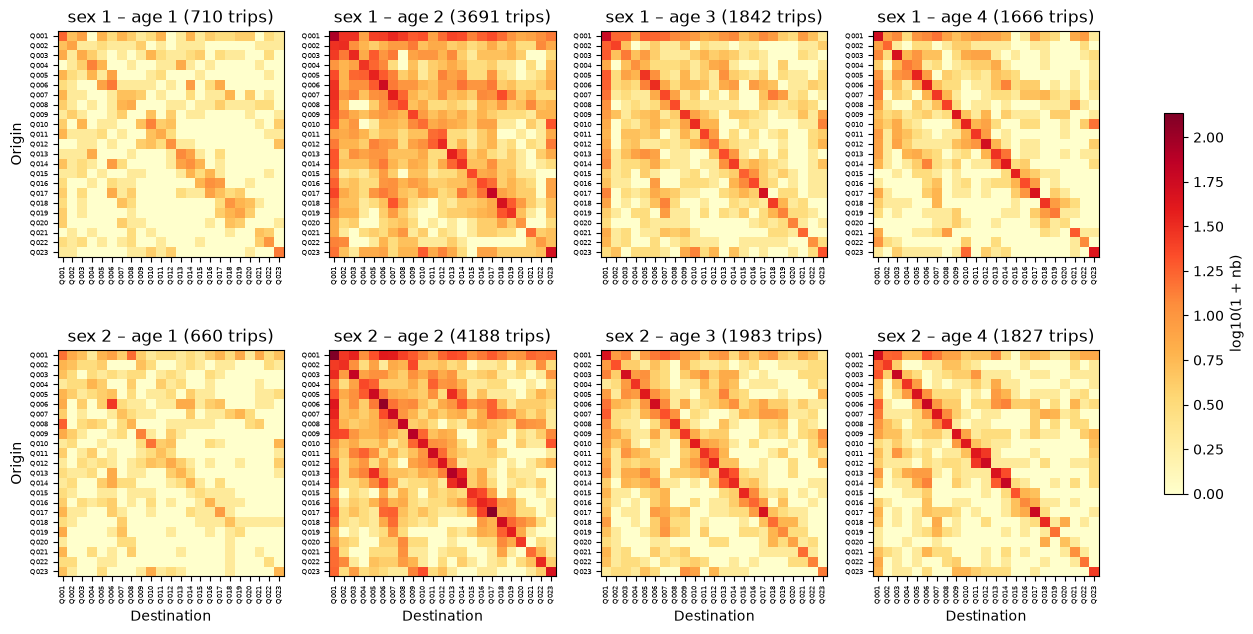

In [40]:
sexe_label = {1: "sex 1", 2: "sex 2"}         
age_label  = {1: "age 1", 2: "age 2", 3: "age 3", 4: "age 4"}

sexes = sorted(dfIMQ["GENDER"].dropna().astype(int).unique())
ages  = sorted(dfIMQ["AGE"].dropna().astype(int).unique())
print("Sex :", sexes, "| Age :", ages)

OD_sexe_age = {}
for s in sexes:
    for a in ages:
        df_sa = dfIMQ[(dfIMQ["GENDER"] == s) & (dfIMQ["AGE"] == a)]
        OD_sexe_age[(s, a)] = od_matrix(df_sa, codes)
        print(f"{sexe_label.get(s, s)} x {age_label.get(a, a)} : {len(df_sa)} trips ({len(df_sa)/len(dfIMQ):.1%})")
vmax = np.log10(max(OD.to_numpy().max() for OD in OD_sexe_age.values()) + 1)

fig, axes = plt.subplots(len(sexes), len(ages), figsize=(4.2 * len(ages), 3.8 * len(sexes)), squeeze=False)

for i, s in enumerate(sexes):
    for j, a in enumerate(ages):
        ax, OD = axes[i][j], OD_sexe_age[(s, a)]
        im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{sexe_label.get(s, s)} – {age_label.get(a, a)} ({OD.to_numpy().sum():.0f} trips)")
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
        if i == len(sexes) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")

fig.colorbar(im, ax=axes, shrink=0.65, label="log10(1 + nb)")
plt.show()



sex 1 x age 1 : 710 trajets (4.3%)
sex 1 x age 2 : 3691 trajets (22.3%)
sex 1 x age 3 : 1842 trajets (11.1%)
sex 1 x age 4 : 1666 trajets (10.1%)
sex 2 x age 1 : 660 trajets (4.0%)
sex 2 x age 2 : 4188 trajets (25.3%)
sex 2 x age 3 : 1983 trajets (12.0%)
sex 2 x age 4 : 1827 trajets (11.0%)


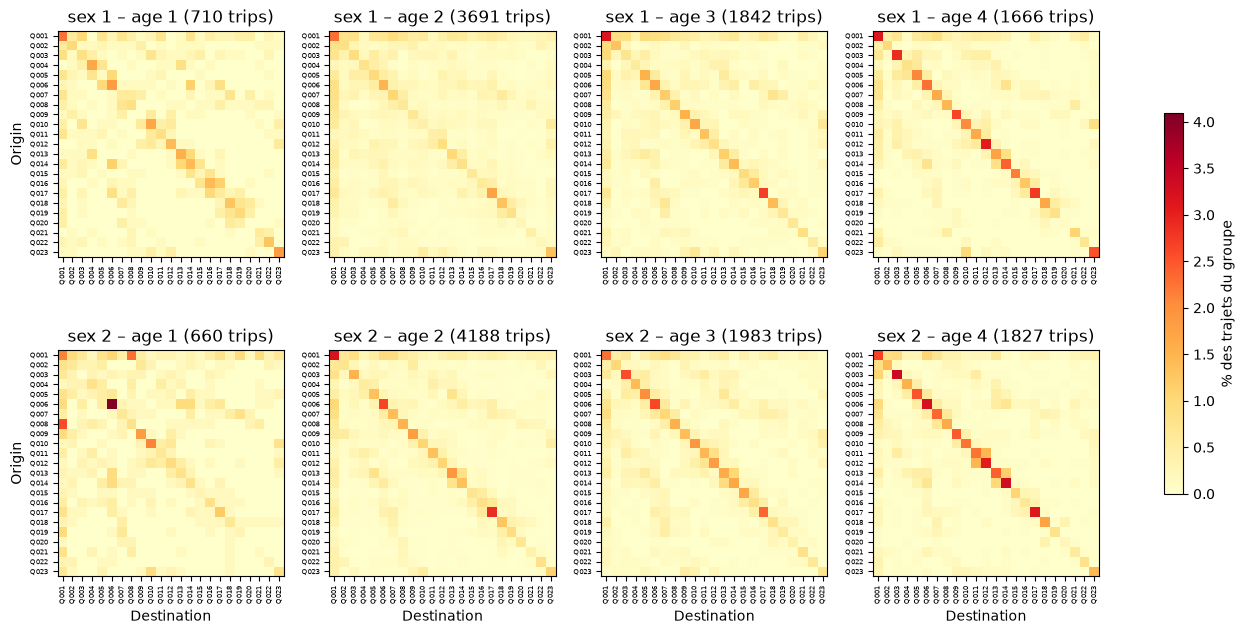

In [41]:

OD_sexe_age = {}
for s in sexes:
    for a in ages:
        df_sa = dfIMQ[(dfIMQ["GENDER"] == s) & (dfIMQ["AGE"] == a)]
        OD_sexe_age[(s, a)] = od_matrix(df_sa, codes)
        print(f"{sexe_label.get(s, s)} x {age_label.get(a, a)} : {len(df_sa)} trajets ({len(df_sa)/len(dfIMQ):.1%})")

vmax = max(pct(OD).max() for OD in OD_sexe_age.values())

fig, axes = plt.subplots(len(sexes), len(ages), figsize=(4.2 * len(ages), 3.8 * len(sexes)), squeeze=False)

for i, s in enumerate(sexes):
    for j, a in enumerate(ages):
        ax, OD = axes[i][j], OD_sexe_age[(s, a)]
        im = ax.imshow(pct(OD), cmap="YlOrRd", vmin=0, vmax=vmax)
        ax.set_title(f"{sexe_label.get(s, s)} – {age_label.get(a, a)} ({OD.to_numpy().sum():.0f} trips)")
        ax.set_xticks(range(len(codes))); ax.set_xticklabels(codes, rotation=90, fontsize=5)
        ax.set_yticks(range(len(codes))); ax.set_yticklabels(codes, fontsize=5)
        if i == len(sexes) - 1: ax.set_xlabel("Destination")
        if j == 0: ax.set_ylabel("Origin")

fig.colorbar(im, ax=axes, shrink=0.65, label="% des trajets du groupe")
plt.show()

Sex keys: [np.int64(1), np.int64(2)] | Age keys: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

=== JS distance between age groups – sex 1 ===
        age 1   age 2   age 3   age 4
age 1  0.0000  0.6835  0.6866  0.6913
age 2  0.6835  0.0000  0.5776  0.6311
age 3  0.6866  0.5776  0.0000  0.6054
age 4  0.6913  0.6311  0.6054  0.0000

=== JS distance between age groups – sex 2 ===
        age 1   age 2   age 3   age 4
age 1  0.0000  0.6565  0.6998  0.7160
age 2  0.6565  0.0000  0.5485  0.5890
age 3  0.6998  0.5485  0.0000  0.5873
age 4  0.7160  0.5890  0.5873  0.0000


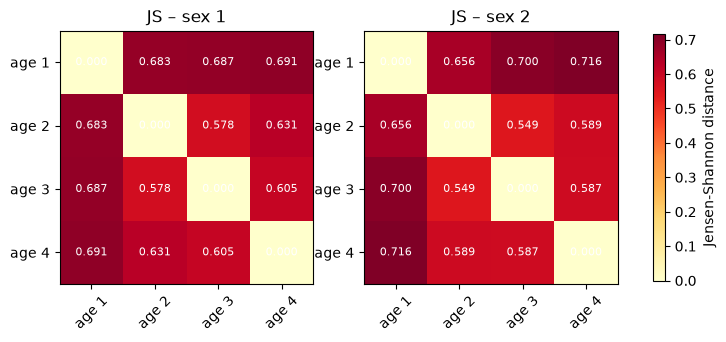

In [42]:
def to_dist(OD):
    """Flatten the OD matrix and normalize it into a probability distribution."""
    v = OD.to_numpy().astype(float).ravel()
    return v / v.sum()

sexes_k = sorted({k[0] for k in OD_sexe_age})
ages_k  = sorted({k[1] for k in OD_sexe_age})
print("Sex keys:", sexes_k, "| Age keys:", ages_k)

JS_same_sex = {}   # {sex: DataFrame (ages x ages)}

for s in sexes_k:
    M = pd.DataFrame(0.0, index=ages_k, columns=ages_k)
    for a1, a2 in combinations(ages_k, 2):
        P = to_dist(OD_sexe_age[(s, a1)])
        Q = to_dist(OD_sexe_age[(s, a2)])
        d = np.sqrt(js_divergence(P, Q))   # remove sqrt if js_divergence already returns the distance
        M.loc[a1, a2] = M.loc[a2, a1] = d
    JS_same_sex[s] = M

    print(f"\n=== JS distance between age groups – {sexe_label.get(s, s)} ===")
    print(M.rename(index=age_label, columns=age_label).round(4))

vmax_js = max(M.to_numpy().max() for M in JS_same_sex.values())

fig, axes = plt.subplots(1, len(sexes_k), figsize=(4.5 * len(sexes_k), 4), squeeze=False)
for k, s in enumerate(sexes_k):
    ax, M = axes[0][k], JS_same_sex[s]
    im = ax.imshow(M.to_numpy(), cmap="YlOrRd", vmin=0, vmax=vmax_js)
    ax.set_title(f"JS – {sexe_label.get(s, s)}")
    ax.set_xticks(range(len(ages_k))); ax.set_xticklabels([age_label.get(a, a) for a in ages_k], rotation=45)
    ax.set_yticks(range(len(ages_k))); ax.set_yticklabels([age_label.get(a, a) for a in ages_k])
    for i in range(len(ages_k)):
        for j in range(len(ages_k)):
            ax.text(j, i, f"{M.iloc[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)

fig.colorbar(im, ax=axes, shrink=0.8, label="Jensen-Shannon distance")
plt.show()

## Q3.c

In [43]:
def load_trips_with_loc(coll, city="Torino"):
    pipe = [
        {"$match": {"city": city, "driving.distance": {"$gt": 0}}},
        {"$project": {
            "_id": 0, "plate": 1,
            "init_date": 1, "final_date": 1, "init_time": 1, "final_time": 1,
            "init_loc": 1, "final_loc": 1,
            "drv_dur": "$driving.duration", "drv_dist": "$driving.distance",
        }},
    ]
    df = pd.DataFrame(coll.aggregate(pipe, allowDiskUse=True))
    df["rental_min"] = (df["final_time"] - df["init_time"]) / 60
    df["drv_dist_km"] = df["drv_dist"] / 1000
    df["init_date"] = pd.to_datetime(df["init_date"])

    df["origin_lon"] = df["init_loc"].apply(lambda x: x["coordinates"][0])
    df["origin_lat"] = df["init_loc"].apply(lambda x: x["coordinates"][1])
    df["destination_lon"] = df["final_loc"].apply(lambda x: x["coordinates"][0])
    df["destination_lat"] = df["final_loc"].apply(lambda x: x["coordinates"][1])
    return df.drop(columns=["init_loc", "final_loc"])


trips_c2g = load_trips_with_loc(pb_coll)
trips_enjoy = load_trips_with_loc(pb_coll_enjoy)

In [44]:
trips_c2g_z = assign_imq_zones(trips_c2g, zones_imq)
trips_enjoy_z = assign_imq_zones(trips_enjoy, zones_imq)
def od_matrix_safe(df, codes):
    m = df["ORI_ZONE"].notna() & df["DST_ZONE"].notna()
    if (~m).any():
        pass
    return od_matrix(df[m], codes)


OD_imq = OD_counts                      
OD_uni = od_matrix_safe(trips_uni_z, codes)
OD_c2g = od_matrix_safe(trips_c2g_z, codes)
OD_enjoy = od_matrix_safe(trips_enjoy_z, codes)

P_imq, P_uni, P_c2g, P_enjoy = (
    OD / OD.to_numpy().sum() for OD in [OD_imq, OD_uni, OD_c2g, OD_enjoy]
)

matrices = [OD_imq, OD_uni, OD_c2g, OD_enjoy]
recap = pd.DataFrame(
    {
        "trips": [int(OD.to_numpy().sum()) for OD in matrices],
        "Same zone part": [
            f"{np.trace(OD.to_numpy()) / OD.to_numpy().sum():.1%}" for OD in matrices
        ],
    },
    index=["IMQ", "Unipol", "Car2Go", "Enjoy"],
)
display(recap)



,trips,Same zone part
IMQ,16567,30.4%
Unipol,480078,46.9%
Car2Go,39190,10.2%
Enjoy,35726,8.3%


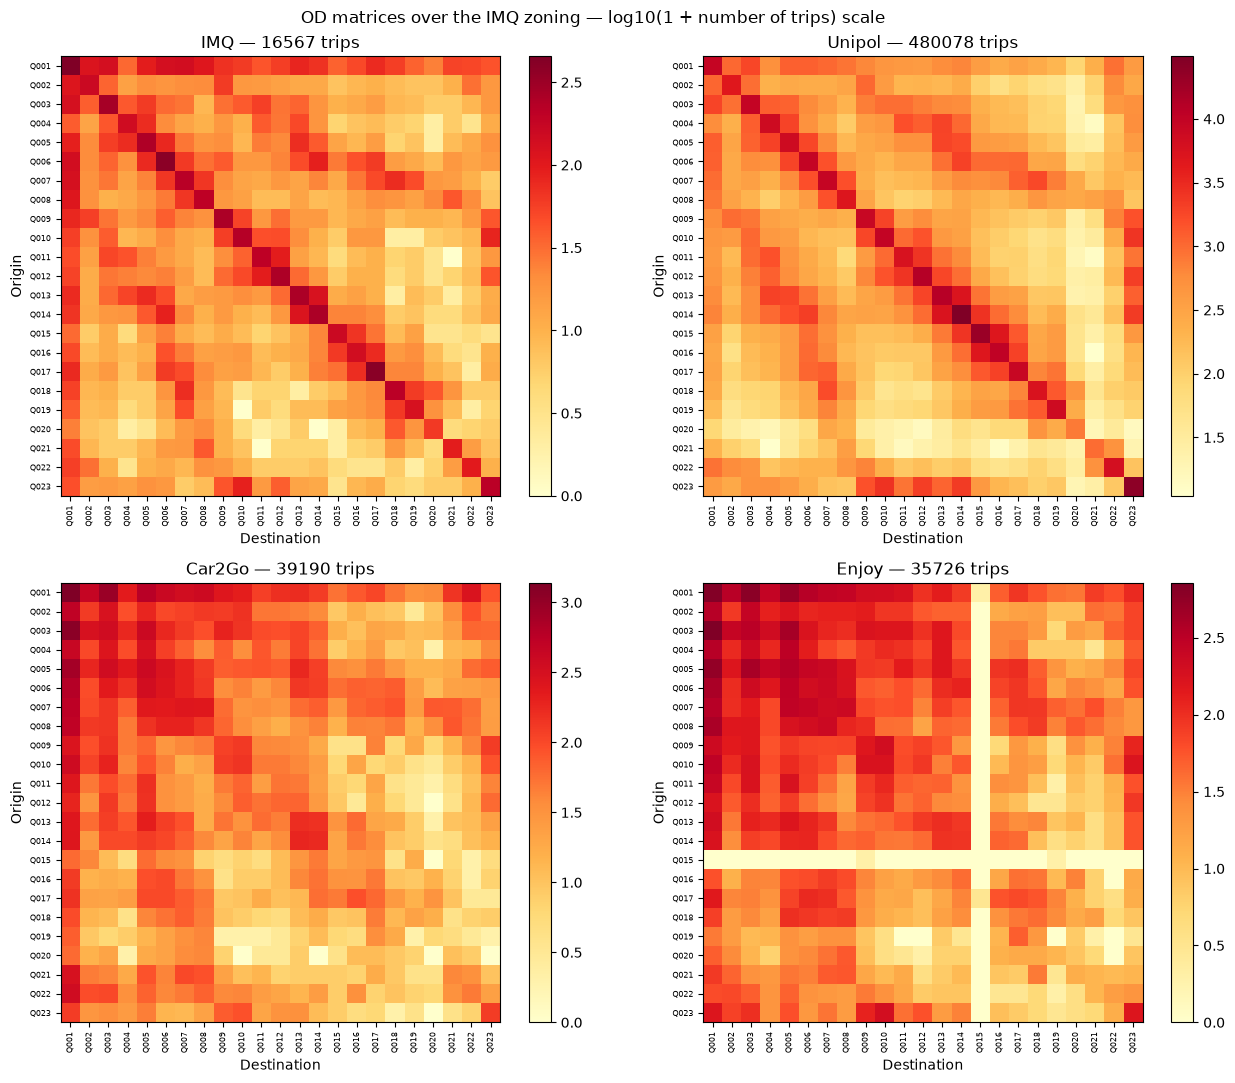

In [45]:
mats = {"IMQ": OD_imq, "Unipol": OD_uni, "Car2Go": OD_c2g, "Enjoy": OD_enjoy}

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, OD) in zip(axes.flat, mats.items()):
    im = ax.imshow(np.log10(OD.to_numpy() + 1), cmap="YlOrRd")
    ax.set_xticks(range(len(codes)))
    ax.set_xticklabels(codes, rotation=90, fontsize=6)
    ax.set_yticks(range(len(codes)))
    ax.set_yticklabels(codes, fontsize=6)
    ax.set_title(f"{name} — {int(OD.to_numpy().sum())} trips")
    ax.set_xlabel("Destination")
    ax.set_ylabel("Origin")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("OD matrices over the IMQ zoning — log10(1 + number of trips) scale")
plt.tight_layout()
plt.show()

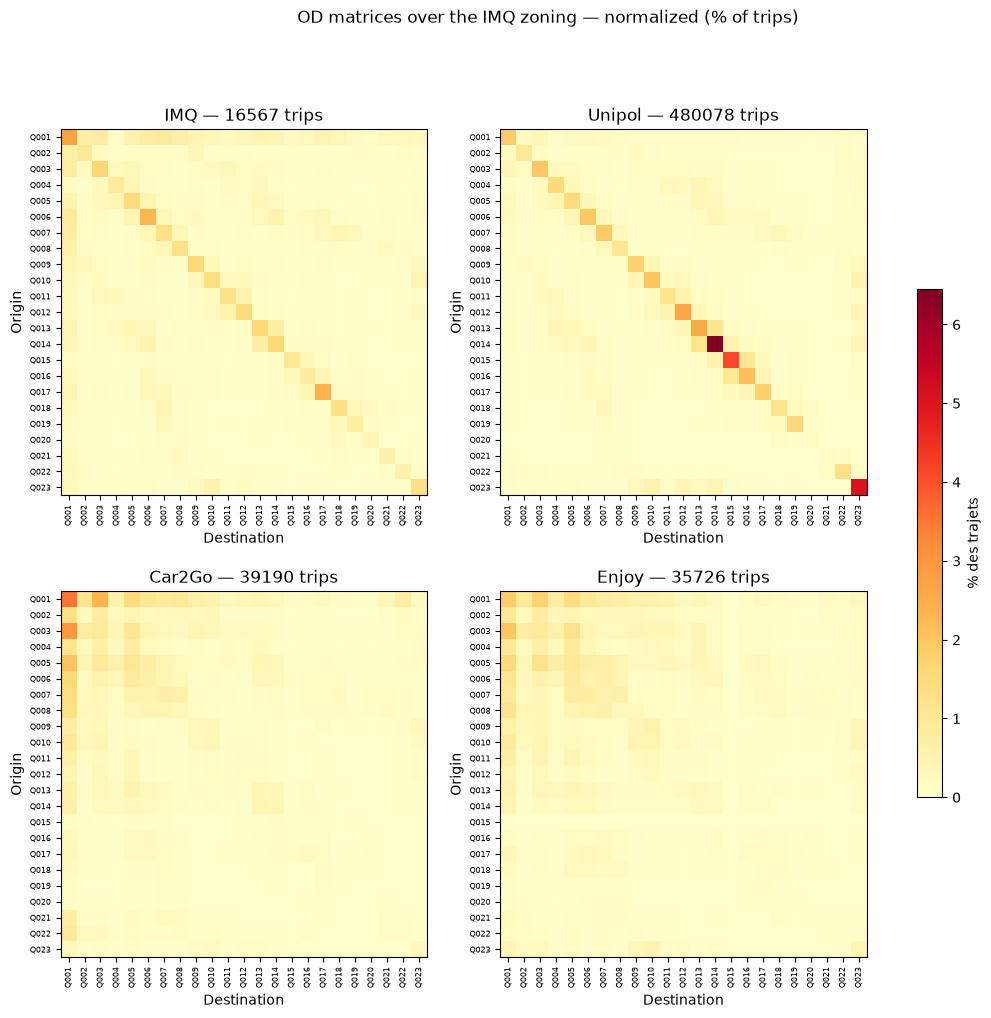

In [46]:
probs = {"IMQ": P_imq, "Unipol": P_uni, "Car2Go": P_c2g, "Enjoy": P_enjoy}
vmax = max(100 * P.to_numpy().max() for P in probs.values())

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for ax, (name, OD) in zip(axes.flat, mats.items()):
    im = ax.imshow(100 * probs[name].to_numpy(), cmap="YlOrRd", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(codes)))
    ax.set_xticklabels(codes, rotation=90, fontsize=6)
    ax.set_yticks(range(len(codes)))
    ax.set_yticklabels(codes, fontsize=6)
    ax.set_title(f"{name} — {int(OD.to_numpy().sum())} trips")
    ax.set_xlabel("Destination")
    ax.set_ylabel("Origin")
fig.colorbar(im, ax=axes, shrink=0.6, label="% des trajets")
fig.suptitle("OD matrices over the IMQ zoning — normalized (% of trips)")
plt.show()

# Explanation of why there is no point in Q15 for Enjoy 

In [47]:
pts = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(trips_enjoy_z.origin_lon, trips_enjoy_z.origin_lat),
    crs="EPSG:4326")
cnt = pts.sjoin(zones_imq[["zone_code", "geometry"]],
                predicate="within")["zone_code"].value_counts()
print(cnt.reindex(codes, fill_value=0).sort_values().head(8))

zone_code
Q015      2
Q019    261
Q020    316
Q022    453
Q021    481
Q016    674
Q018    729
Q017    889
Name: count, dtype: int64


In [48]:
m = zones_imq.explore(tiles="OpenStreetMap",
                      style_kwds={"fillOpacity": 0.05, "weight": 1})
zones_imq[zones_imq.zone_code == "Q015"].explore(
    m=m, color="red", style_kwds={"fillOpacity": 0.4, "weight": 3},
    tooltip=["zone_code", "zone_name", "area_km2"])
pts.sample(3000).explore(m=m, color="blue", marker_type="circle_marker",
                         marker_kwds={"radius": 2, "fill": True})
m   # la zone rouge contient-elle le moindre point bleu ?

# Comparison between Car2Go Enjoy and IMQ by gender and age.

In [49]:

GENDER_LABEL = {1: "Men", 2: "Women"}     

rows = []
for (sex, age), grp in dfIMQ.groupby(["GENDER", "AGE"]):
    OD_g = od_matrix(grp, codes)                              
    n = int(OD_g.to_numpy().sum())
    P_g = OD_g.to_numpy() / n                                
    rows.append({
        "sex":    GENDER_LABEL.get(sex, sex),
        "age":    age,
        "trips":  n,
        "JS_Car2Go": round(js_divergence(P_g, P_c2g.to_numpy()), 4),
        "JS_Enjoy":  round(js_divergence(P_g, P_enjoy.to_numpy()), 4),
    })

js_age_sex = pd.DataFrame(rows).sort_values(["sex", "age"]).reset_index(drop=True)
js_age_sex["closest_source"] = np.where(
    js_age_sex["JS_Car2Go"] <= js_age_sex["JS_Enjoy"], "Car2Go", "Enjoy")

print("Jensen-Shannon distance (0 = identical) by age × sex group")
display(js_age_sex)

# Summary: which group is most similar to each source?
for src in ["Car2Go", "Enjoy"]:
    best = js_age_sex.sort_values(f"JS_{src}").iloc[0]
    print(f"Closest profile to {src}: {best.sex}, age {best.age} "
          f"(JS = {best[f'JS_{src}']:.4f}, {int(best.trips)} trips)")

Jensen-Shannon distance (0 = identical) by age × sex group


,sex,age,trips,JS_Car2Go,JS_Enjoy,closest_source
0,Men,1,710,0.5463,0.5608,Car2Go
1,Men,2,3691,0.3678,0.3782,Car2Go
2,Men,3,1842,0.4354,0.4506,Car2Go
3,Men,4,1666,0.5071,0.5221,Car2Go
4,Women,1,660,0.5042,0.5192,Car2Go
5,Women,2,4188,0.4038,0.4230,Car2Go
6,Women,3,1983,0.4557,0.4756,Car2Go
7,Women,4,1827,0.5232,0.5398,Car2Go


Closest profile to Car2Go: Men, age 2 (JS = 0.3678, 3691 trips)
Closest profile to Enjoy: Men, age 2 (JS = 0.3782, 3691 trips)


# Comparison of the 3 OD Matrices 

Jensen-Shannon distance between sources (0 = identical distributions)


,IMQ,Unipol,Car2Go,Enjoy
IMQ,0.0000,0.3086,0.3765,0.3958
Unipol,0.3086,0.0000,0.5443,0.5554
Car2Go,0.3765,0.5443,0.0000,0.2073
Enjoy,0.3958,0.5554,0.2073,0.0000


,pair,JS,closest
0,Car2Go ↔ Enjoy,0.2073,True
1,IMQ ↔ Unipol,0.3086,False
2,IMQ ↔ Car2Go,0.3765,False
3,IMQ ↔ Enjoy,0.3958,False
4,Unipol ↔ Car2Go,0.5443,False
5,Unipol ↔ Enjoy,0.5554,False


Closest pair  : Car2Go ↔ Enjoy (JS = 0.2073)
Farthest pair : Unipol ↔ Enjoy (JS = 0.5554)


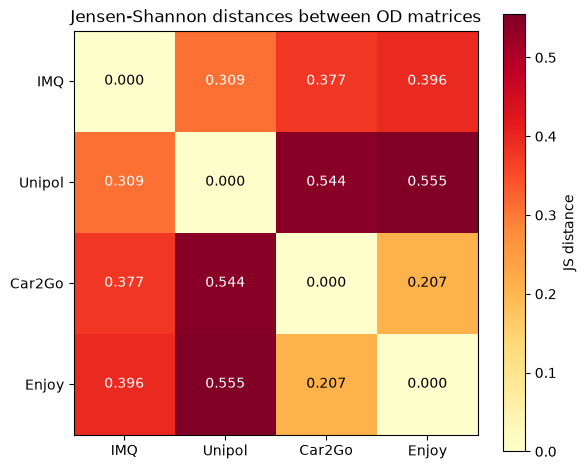

In [50]:
prob = {"IMQ": P_imq, "Unipol": P_uni, "Car2Go": P_c2g, "Enjoy": P_enjoy}
# Variant: compare against the IMQ reweighted by the sampling weights
# prob["IMQ"] = OD_w.to_numpy() / OD_w.to_numpy().sum()

# 4x4 matrix of pairwise JS distances
js_tab = pd.DataFrame(0.0, index=prob.keys(), columns=prob.keys())
for a, b in combinations(prob.keys(), 2):
    v = js_divergence(prob[a].to_numpy(), prob[b].to_numpy())
    js_tab.loc[a, b] = js_tab.loc[b, a] = round(v, 4)

print("Jensen-Shannon distance between sources (0 = identical distributions)")
display(js_tab)

# Ranking of pairs: from closest to farthest
pairs = pd.DataFrame(
    [{"pair": f"{a} ↔ {b}",
      "JS": js_divergence(prob[a].to_numpy(), prob[b].to_numpy())}
     for a, b in combinations(prob.keys(), 2)]
).sort_values("JS").reset_index(drop=True)
pairs["closest"] = pairs["JS"] == pairs["JS"].min()
display(pairs.round(4))

print(f"Closest pair  : {pairs.iloc[0].pair} (JS = {pairs.iloc[0].JS:.4f})")
print(f"Farthest pair : {pairs.iloc[-1].pair} (JS = {pairs.iloc[-1].JS:.4f})")

# Summary heatmap
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(js_tab.to_numpy(), cmap="YlOrRd")
ax.set_xticks(range(len(js_tab))); ax.set_xticklabels(js_tab.columns)
ax.set_yticks(range(len(js_tab))); ax.set_yticklabels(js_tab.index)
for i in range(len(js_tab)):
    for j in range(len(js_tab)):
        ax.text(j, i, f"{js_tab.iloc[i, j]:.3f}", ha="center", va="center",
                color="white" if js_tab.iloc[i, j] > js_tab.to_numpy().max()/2 else "black")
fig.colorbar(im, label="JS distance")
ax.set_title("Jensen-Shannon distances between OD matrices")
plt.tight_layout(); plt.show()